<a href="https://colab.research.google.com/github/kavita9404/GUM-Compliant-PM2.5-Measurement-Calibration-for-Low-Cost-Optical-Particle-Counters/blob/main/LowCostOPCs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q xgboost lightgbm catboost shap scikit-learn \
#               pandas numpy matplotlib seaborn scipy psutil

In [2]:
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use('Agg')          # non-interactive: prevents Colab debug-text bleed
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
from scipy import stats
from scipy.interpolate import interp1d
from scipy.optimize import nnls
import time, gc, os, warnings, psutil
warnings.filterwarnings('ignore')

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import RidgeCV, LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.kernel_approximation import Nystroem
from sklearn.pipeline import make_pipeline
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
import shap

plt.rcParams.update({
    'font.family':       'DejaVu Serif',
    'axes.titlesize':    13,  'axes.labelsize':   12,
    'xtick.labelsize':   10,  'ytick.labelsize':  10,
    'legend.fontsize':   10,  'savefig.dpi':      300,
    'savefig.bbox':      'tight',
    'savefig.facecolor': 'white',  'figure.facecolor': 'white',
    'axes.facecolor':    'white',
    'axes.spines.top':   False,    'axes.spines.right': False,
})

NAVY   = '#1A3557';  MID    = '#2563A8';  LIGHT  = '#D6E4F0'
AMBER  = '#E07B2A';  GREEN  = '#2E7D32';  RED    = '#C62828'
TEAL   = '#00695C';  PURPLE = '#6A1B9A';  ORANGE = '#E65100'
OUTDIR = '/content/'

def save_fig(name):
    plt.savefig(os.path.join(OUTDIR, name), dpi=300,
                bbox_inches='tight', facecolor='white')
    plt.show(); plt.close()
    print(f"  ✓ {name}")

def metrics(yt, yp, label=''):
    rmse = np.sqrt(mean_squared_error(yt, yp))
    mae  = mean_absolute_error(yt, yp)
    mbe  = np.mean(yp - yt)
    r2   = r2_score(yt, yp)
    print(f"  {label:<38} RMSE={rmse:.3f}  MAE={mae:.3f}  "
          f"MBE={mbe:+.3f}  R²={r2:.4f}")
    return rmse, mae, mbe, r2

import xgboost as _x, lightgbm as _l, catboost as _c, sklearn as _s
print("Library versions:", {"xgboost": _x.__version__, "lightgbm": _l.__version__,
      "catboost": _c.__version__, "scikit-learn": _s.__version__, "numpy": np.__version__,
      "pandas": pd.__version__})
print("✓ Imports done")

Library versions: {'xgboost': '3.4.1', 'lightgbm': '4.6.0', 'catboost': '1.2.10', 'scikit-learn': '1.6.1', 'numpy': '2.1.3', 'pandas': '2.2.3'}
✓ Imports done


In [3]:
print("\n" + "═"*70)
print("MEASUREMENT TRACEABILITY DECLARATION  [N1]")
print("═"*70)
TRACEABILITY = {
    "Reference instrument":      "Met One BAM-1020 Beta Attenuation Monitor",
    "Measurement principle":     "Beta-ray attenuation of PM2.5 collected on "
                                 "a glass fibre filter tape",
    "Measurement site network":  "UK Automatic Urban and Rural Network (AURN)",
    "Calibration standard":      "Gravimetric PM2.5 filter reference "
                                 "(SI-traceable via NPL mass standards)",
    "Reference uncertainty":     "U_ref = 5% of reading (k=2, ~95% coverage), "
                                 "per MCERTS performance standard",
    "Time resolution":           "1-hour averages (as provided in QUANT dataset)",
    "Dataset DOI":               "https://doi.org/10.1038/s41597-024-03767-2",
    "Calibration period":        "December 2019 – October 2022",
    "Cities":                    "Manchester, London, York (UK)",
    "Sensor under calibration":  "Commercial low-cost optical particle counter "
                                 "(OPC), out-of-box factory-default version",
    "Sensor principle":          "Laser Mie scattering — scattered light "
                                 "intensity proportional to particle concentration",
    "Traceability chain":        "OPC raw signal → ML calibration function "
                                 "→ calibrated PM2.5 → BAM-1020 "
                                 "→ gravimetric reference → SI mass unit (kg)",
}
for k, v in TRACEABILITY.items():
    print(f"  {k:<30}: {v}")


══════════════════════════════════════════════════════════════════════
MEASUREMENT TRACEABILITY DECLARATION  [N1]
══════════════════════════════════════════════════════════════════════
  Reference instrument          : Met One BAM-1020 Beta Attenuation Monitor
  Measurement principle         : Beta-ray attenuation of PM2.5 collected on a glass fibre filter tape
  Measurement site network      : UK Automatic Urban and Rural Network (AURN)
  Calibration standard          : Gravimetric PM2.5 filter reference (SI-traceable via NPL mass standards)
  Reference uncertainty         : U_ref = 5% of reading (k=2, ~95% coverage), per MCERTS performance standard
  Time resolution               : 1-hour averages (as provided in QUANT dataset)
  Dataset DOI                   : https://doi.org/10.1038/s41597-024-03767-2
  Calibration period            : December 2019 – October 2022
  Cities                        : Manchester, London, York (UK)
  Sensor under calibration      : Commercial low-cost o

In [4]:
print("\n" + "═"*70)
print("SENSOR PHYSICS SUMMARY  [N3]")
print("═"*70)
PHYSICS = [
    ("Measurement mechanism",
     "Optical particle counters (OPCs) measure PM2.5 via laser Mie scattering. "
     "A 780 nm laser illuminates particles passing through the sensing volume. "
     "Scattered photons are collected by a photodetector; pulse height and count "
     "rate are used to estimate particle number concentration and size distribution. "
     "PM2.5 mass concentration is inferred via an internal conversion factor."),
    ("Hygroscopic growth bias",
     "At RH > 65%, hygroscopic aerosol components (ammonium sulphate, sea salt, "
     "organic matter) absorb water and swell. The κ-Köhler growth factor "
     "f(RH) = (1 + κ·RH/(1−RH))^(1/3) describes this: for κ=0.3 (typical urban "
     "aerosol), f(RH=80%)≈1.35, meaning the optical cross-section increases 35% "
     "without any increase in dry particle mass. This causes systematic OPC "
     "overestimation at high humidity — the primary calibration target."),
    ("Temperature cross-sensitivity",
     "Photodetector gain and laser power vary with temperature (~0.1% per °C). "
     "Additionally, temperature affects aerosol phase (liquid vs. crystalline), "
     "altering scattering efficiency. At T < 5°C, reduced evaporation rates "
     "maintain higher particle water content for the same RH, amplifying the "
     "hygroscopic bias."),
    ("Particle size distribution effects",
     "The Mie scattering efficiency varies non-linearly with particle diameter "
     "relative to laser wavelength. Coarse particles (PM10) scatter more "
     "efficiently per unit mass, causing bias when the PM2.5/PM10 ratio shifts. "
     "Including PM10 as a feature allows the model to correct for size "
     "distribution variability."),
    ("Why ML calibration is necessary",
     "Physical correction models using single-parameter humidity corrections "
     "(e.g., Zacharias et al.) achieve R²≈0.80 but fail to capture non-linear "
     "T×RH interactions and site-specific aerosol chemistry. ML calibration "
     "learns these complex multi-variable response surfaces from co-location "
     "data, achieving R²>0.85 while maintaining GUM-compliant uncertainty."),
]
for title, text in PHYSICS:
    print(f"\n  [{title}]")
    # wrap text at 75 chars
    words = text.split(); line = "    "
    for w in words:
        if len(line)+len(w)+1 > 78:
            print(line); line = "    " + w + " "
        else:
            line += w + " "
    print(line)


══════════════════════════════════════════════════════════════════════
SENSOR PHYSICS SUMMARY  [N3]
══════════════════════════════════════════════════════════════════════

  [Measurement mechanism]
    Optical particle counters (OPCs) measure PM2.5 via laser Mie scattering. 
    A 780 nm laser illuminates particles passing through the sensing volume. 
    Scattered photons are collected by a photodetector; pulse height and 
    count rate are used to estimate particle number concentration and size 
    distribution. PM2.5 mass concentration is inferred via an internal 
    conversion factor. 

  [Hygroscopic growth bias]
    At RH > 65%, hygroscopic aerosol components (ammonium sulphate, sea salt, 
    organic matter) absorb water and swell. The κ-Köhler growth factor f(RH) 
    = (1 + κ·RH/(1−RH))^(1/3) describes this: for κ=0.3 (typical urban 
    aerosol), f(RH=80%)≈1.35, meaning the optical cross-section increases 35% 
    without any increase in dry particle mass. This causes sys

In [5]:
print("\n" + "═"*70)
print("FEATURE SELECTION JUSTIFICATION TABLE  [N4]")
print("═"*70)
FEATURE_JUSTIFICATION = [
    ("pm25_sensor",     "Primary signal",       "Raw OPC PM2.5 reading; the uncalibrated measurand to be corrected"),
    ("temperature",     "Environmental",        "Affects photodetector gain and aerosol phase; Type B sensitivity"),
    ("rh",              "Environmental",        "Drives hygroscopic swelling (κ-Köhler); strongest bias source"),
    ("dew_point",       "Derived met.",         "Encodes absolute moisture; partially independent of T and RH"),
    ("rh_sq",           "Nonlinear term",       "Captures the accelerating hygroscopic effect above 70% RH"),
    ("rh_pm_inter",     "Interaction",          "Concentration-dependent correction: higher PM2.5 → larger absolute error"),
    ("t_rh_inter",      "Interaction",          "Joint T×RH effect on water uptake not captured by marginal terms"),
    ("pm_ratio",        "Size distribution",    "PM2.5/PM10 ratio proxies aerosol size distribution shifts"),
    ("pm10_sensor",     "Co-pollutant",         "Co-varies with PM2.5; improves prediction at high loadings"),
    ("no2_sen",         "Chemistry proxy",      "Traffic-related NO₂ indicates combustion aerosol composition"),
    ("o3_sen",          "Chemistry proxy",      "Photochemical O₃ indicates secondary aerosol formation regime"),
    ("hour_sin/cos",    "Temporal cyclic",      "Diurnal variation in traffic, boundary layer, and RH"),
    ("dow_sin/cos",     "Temporal cyclic",      "Weekday/weekend traffic and emission pattern differences"),
    ("doy_sin/cos",     "Temporal cyclic",      "Seasonal variation in aerosol composition and mixing height"),
    ("pm25_roll24",     "History/persistence",  "24-h rolling mean captures pollution episode persistence"),
    ("pm25_roll72",     "History/persistence",  "72-h rolling mean captures longer synoptic-scale episodes"),
    ("pm25_roll_std",   "Variability",          "Rolling SD distinguishes stable baseline from episodic peaks"),
    ("pressure_sen",    "Meteorological",       "Pressure correlates with boundary layer height and ventilation"),
    ("site_*",          "Multi-city",           "Dummy variables capture site-specific aerosol chemistry offsets"),
]
print(f"  {'Feature':<18} {'Category':<20} {'Physical Justification'}")
print("  " + "-"*68)
for feat, cat, reason in FEATURE_JUSTIFICATION:
    print(f"  {feat:<18} {cat:<20} {reason}")



══════════════════════════════════════════════════════════════════════
FEATURE SELECTION JUSTIFICATION TABLE  [N4]
══════════════════════════════════════════════════════════════════════
  Feature            Category             Physical Justification
  --------------------------------------------------------------------
  pm25_sensor        Primary signal       Raw OPC PM2.5 reading; the uncalibrated measurand to be corrected
  temperature        Environmental        Affects photodetector gain and aerosol phase; Type B sensitivity
  rh                 Environmental        Drives hygroscopic swelling (κ-Köhler); strongest bias source
  dew_point          Derived met.         Encodes absolute moisture; partially independent of T and RH
  rh_sq              Nonlinear term       Captures the accelerating hygroscopic effect above 70% RH
  rh_pm_inter        Interaction          Concentration-dependent correction: higher PM2.5 → larger absolute error
  t_rh_inter         Interaction        

In [6]:
from google.colab import files
print("Upload the three QUANT CSV files:")
uploaded = files.upload()
print("✓ Uploaded:", list(uploaded.keys()))

Upload the three QUANT CSV files:


Saving QUANT_DuplicateRef_hourly.csv to QUANT_DuplicateRef_hourly.csv
Saving QUANT_Reference_hourly.csv to QUANT_Reference_hourly.csv
Saving QUANT_SensorSystems_hourly.csv to QUANT_SensorSystems_hourly.csv
✓ Uploaded: ['QUANT_DuplicateRef_hourly.csv', 'QUANT_Reference_hourly.csv', 'QUANT_SensorSystems_hourly.csv']


In [7]:
print("\n" + "═"*70)
print("CALIBRATION PROCEDURE  [N6]")
print("═"*70)
PROCEDURE = [
    ("Step 1: Data ingestion",
     "Three QUANT CSV files in long format (time|location|measurand|measurement). "
     "Pivot to wide format using pivot_table(aggfunc='mean') per timestamp×location. "
     "Timestamps parsed to UTC-aware datetime; time zone awareness preserved throughout."),
    ("Step 2: Sensor version selection",
     "Only 'out-of-box' sensor readings selected — factory-default uncalibrated "
     "output. This ensures all calibration improvement is attributable to the ML "
     "framework, not manufacturer pre-processing."),
    ("Step 3: Merge & T/RH sourcing",
     "Reference and sensor wide tables merged on timestamp+location (inner join). "
     "Temperature and RelHumidity sourced from the reference file (complete coverage); "
     "sensor T/RH is incomplete due to 'out-of-box' version not logging meteorology."),
    ("Step 4: Quality control",
     "Per-city stratified QC: (i) drop null primary variables; "
     "(ii) physical range filters (PM: 0–500 µg m⁻³, T: −20–60°C, RH: 0–100%); "
     "(iii) rolling 48-h z-score filter (reject >5σ). Applied per-city to avoid "
     "cross-city outlier contamination."),
    ("Step 5: Feature engineering",
     "21 features constructed from merged dataset. All features standardised to "
     "zero mean and unit variance using StandardScaler fitted on training data only. "
     "Rolling statistics computed per-city using groupby().transform() to prevent "
     "cross-city temporal leakage."),
    ("Step 6: Chronological split",
     "Data split by time: first 67% = training+validation, last 33% = held-out test. "
     "Within training: last 20% = validation for early stopping. "
     "No random shuffling. Rationale: sensor calibration must generalise forward "
     "in time, not backward — temporal leakage would inflate reported accuracy."),
    ("Step 7: Model training",
     "Four base learners (RF, XGBoost, LightGBM, CatBoost) trained independently on the "
     "training set; a fifth candidate (Nystroem-Ridge) was evaluated and rejected because "
     "of unstable extrapolation. "
     "Non-negative least squares (NNLS) stacking meta-learner trained on "
     "validation-set predictions. NNLS enforces non-negative weights, preventing "
     "the cancellation artefacts observed with unconstrained Ridge regression."),
    ("Step 8: GUM uncertainty propagation",
     "Seven uncertainty components evaluated per JCGM 100:2008. "
     "Components combined as root-sum-of-squares (uncorrelated sources). "
     "Type B contributions of T, RH and PM10 obtained by perturbing each input by plus and "
     "minus its standard uncertainty and passing it through the final ensemble (derived "
     "features recomputed). Empirical coverage validated against nominal k=2 level."),
]
for title, text in PROCEDURE:
    print(f"\n  {title}:")
    words = text.split(); line = "    "
    for w in words:
        if len(line)+len(w)+1 > 78: print(line); line = "    " + w + " "
        else: line += w + " "
    print(line)

# ── Now load the data ─────────────────────────────────────────────────────────
print("\nLoading Reference file …")
ref = pd.read_csv('QUANT_Reference_hourly.csv', low_memory=False)
ref['time'] = pd.to_datetime(ref['time'], utc=True, errors='coerce')
ref = ref.dropna(subset=['time'])

ref_wide = ref.pivot_table(
    index=['time','location'], columns='measurand',
    values='measurement', aggfunc='mean').reset_index()
ref_wide.columns.name = None
ref_wide = ref_wide.rename(columns={
    'time':'datetime',    'PM2.5':'pm25_ref',
    'PM10':'pm10_ref',    'Temperature':'temperature',
    'RelHumidity':'rh',   'Pressure':'pressure_ref',
    'NO':'no_ref',        'NO2':'no2_ref',   'O3':'o3_ref'})
print(f"  Reference wide: {ref_wide.shape}  "
      f"cities: {ref_wide['location'].unique().tolist()}")
del ref; gc.collect()

print("Loading Sensor file (~90 sec) …")
sen = pd.read_csv('QUANT_SensorSystems_hourly.csv', low_memory=False)
sen['time'] = pd.to_datetime(sen['time'], utc=True, errors='coerce')
sen = sen.dropna(subset=['time'])
print(f"  Total rows: {len(sen):,}  versions: {sen['version'].unique().tolist()}")
sen_oob = sen[sen['version'] == 'out-of-box'].copy()
print(f"  Out-of-box rows: {len(sen_oob):,}")
del sen; gc.collect()

sen_wide = sen_oob.pivot_table(
    index=['time','location'], columns='measurand',
    values='measurement', aggfunc='mean').reset_index()
sen_wide.columns.name = None
sen_wide = sen_wide.rename(columns={
    'time':'datetime',    'PM2.5':'pm25_sensor',
    'PM10':'pm10_sensor', 'Pressure':'pressure_sen',
    'RelHumidity':'rh_sen','Temperature':'temperature_sen',
    'NO':'no_sen',        'NO2':'no2_sen',   'O3':'o3_sen'})
del sen_oob; gc.collect()

print("Loading DuplicateRef file …")
dup = pd.read_csv('QUANT_DuplicateRef_hourly.csv', low_memory=False)
dup['time'] = pd.to_datetime(dup['time'], utc=True, errors='coerce')
dup_pm = dup[dup['measurand']=='PM2.5'][['time','location','measurement']].copy()
dup_pm = dup_pm.rename(columns={'time':'datetime','measurement':'pm25_dup'})
del dup; gc.collect()

df = pd.merge(ref_wide, sen_wide, on=['datetime','location'], how='inner')
df['datetime'] = pd.to_datetime(df['datetime'], utc=True, errors='coerce')
df = df.set_index('datetime').sort_index()
print(f"\n✓ Merged: {len(df):,} rows × {len(df.columns)} columns")
print(f"  Date range: {df.index.min().date()} → {df.index.max().date()}")
print(f"  Cities: {df['location'].value_counts().to_dict()}")
del ref_wide, sen_wide; gc.collect()



══════════════════════════════════════════════════════════════════════
CALIBRATION PROCEDURE  [N6]
══════════════════════════════════════════════════════════════════════

  Step 1: Data ingestion:
    Three QUANT CSV files in long format 
    (time|location|measurand|measurement). Pivot to wide format using 
    pivot_table(aggfunc='mean') per timestamp×location. Timestamps parsed to 
    UTC-aware datetime; time zone awareness preserved throughout. 

  Step 2: Sensor version selection:
    Only 'out-of-box' sensor readings selected — factory-default uncalibrated 
    output. This ensures all calibration improvement is attributable to the 
    ML framework, not manufacturer pre-processing. 

  Step 3: Merge & T/RH sourcing:
    Reference and sensor wide tables merged on timestamp+location (inner 
    join). Temperature and RelHumidity sourced from the reference file 
    (complete coverage); sensor T/RH is incomplete due to 'out-of-box' 
    version not logging meteorology. 

  Step 4

0

In [8]:
n0 = len(df)
print(f'QC step 0  merged rows               : {n0:,}')
df = df.dropna(subset=['pm25_ref','pm25_sensor','temperature','rh'])
print(f'QC step 1  after dropping missing    : {len(df):,}')
df = df[(df['pm25_ref']    >  0) & (df['pm25_ref']    < 500)]
df = df[(df['pm25_sensor'] >  0) & (df['pm25_sensor'] < 500)]
df = df[(df['rh']          >  0) & (df['rh']          <= 100)]
df = df[(df['temperature'] > -20) & (df['temperature'] < 60)]
print(f'QC step 2  after physical range filters: {len(df):,}')

clean_parts = []
for city, grp in df.groupby('location'):
    for col in ['pm25_ref','pm25_sensor']:
        mu    = grp[col].rolling('48h', min_periods=6).mean()
        sigma = grp[col].rolling('48h', min_periods=6).std().fillna(grp[col].std())
        grp   = grp[np.abs(grp[col]-mu) < 5*sigma]
    clean_parts.append(grp)
df = pd.concat(clean_parts).sort_index()
print(f'QC step 3  after 48-h z-score filter  : {len(df):,}')

print(f"QC: {n0:,} → {len(df):,} rows  ({100*(n0-len(df))/n0:.1f}% removed)")
print(f"City distribution:\n{df['location'].value_counts().to_string()}")

QC step 0  merged rows               : 65,292
QC step 1  after dropping missing    : 22,964
QC step 2  after physical range filters: 22,959
QC step 3  after 48-h z-score filter  : 22,810
QC: 65,292 → 22,810 rows  (65.1% removed)
City distribution:
location
Manchester    22810


In [9]:
# Meteorological features
df['dew_point']    = df['temperature'] - ((100 - df['rh']) / 5)
df['rh_sq']        = df['rh'] ** 2
df['rh_pm_inter']  = df['rh'] * df['pm25_sensor']
df['t_rh_inter']   = df['temperature'] * df['rh']
df['pm_ratio']     = df['pm25_sensor'] / (df['pm10_sensor'].clip(lower=0.1))
# Fill chemistry proxies with 0 if absent
for col in ['no2_sen','o3_sen']:
    if col in df.columns:
        df[col] = df[col].fillna(0)
    else:
        df[col] = 0.0
# Temporal cyclic features
df['hour_sin']  = np.sin(2*np.pi*df.index.hour/24)
df['hour_cos']  = np.cos(2*np.pi*df.index.hour/24)
df['dow_sin']   = np.sin(2*np.pi*df.index.dayofweek/7)
df['dow_cos']   = np.cos(2*np.pi*df.index.dayofweek/7)
df['doy_sin']   = np.sin(2*np.pi*df.index.dayofyear/365)
df['doy_cos']   = np.cos(2*np.pi*df.index.dayofyear/365)
# Rolling statistics (per-city to prevent leakage)
for col, w, mn in [('pm25_roll24',24,6),('pm25_roll72',72,12),('pm25_roll_std',24,6)]:
    func = 'mean' if col != 'pm25_roll_std' else 'std'
    df[col] = df.groupby('location')['pm25_sensor'].transform(
        lambda x, w=w, mn=mn, f=func:
            x.rolling(w, min_periods=mn).mean() if f=='mean'
            else x.rolling(w, min_periods=mn).std())
# Multi-city site dummies  [P2]
site_dummies = pd.get_dummies(df['location'], prefix='site', drop_first=True)
df = pd.concat([df, site_dummies], axis=1)
site_cols = site_dummies.columns.tolist()

# Build feature list
BASE = ['pm25_sensor','temperature','rh','dew_point',
        'rh_sq','rh_pm_inter','t_rh_inter',
        'hour_sin','hour_cos','dow_sin','dow_cos','doy_sin','doy_cos',
        'pm25_roll24','pm25_roll72','pm25_roll_std']
OPTIONAL = ['pm10_sensor','pressure_sen','pm_ratio','no2_sen','o3_sen']
FEATURES = BASE.copy()
for f in OPTIONAL:
    if f in df.columns and df[f].notna().mean() > 0.3:
        FEATURES.append(f)
FEATURES += site_cols
TARGET = 'pm25_ref'

df = df.dropna(subset=FEATURES + [TARGET])
print(f"\n✓ Features ({len(FEATURES)}): {FEATURES}")
print(f"✓ Final dataset: {len(df):,} rows")

FEAT_LABELS = {
    'pm25_sensor':'PM2.5 Sensor (raw)', 'temperature':'Temperature (°C)',
    'rh':'Rel. Humidity (%)',           'dew_point':'Dew Point (°C)',
    'rh_sq':'RH² (nonlinear)',          'rh_pm_inter':'RH × PM2.5',
    't_rh_inter':'T × RH',             'pm_ratio':'PM2.5/PM10 ratio',
    'hour_sin':'Hour sin',              'hour_cos':'Hour cos',
    'dow_sin':'DOW sin',                'dow_cos':'DOW cos',
    'doy_sin':'DOY sin',                'doy_cos':'DOY cos',
    'pm25_roll24':'PM2.5 Roll 24h',     'pm25_roll72':'PM2.5 Roll 72h',
    'pm25_roll_std':'PM2.5 Roll SD',    'pm10_sensor':'PM10 Sensor',
    'pressure_sen':'Pressure',          'no2_sen':'NO₂ (sensor)',
    'o3_sen':'O₃ (sensor)',
}
feat_labels = [FEAT_LABELS.get(f, f) for f in FEATURES]
print('Share of non-zero values (0 means the column is only zero-filled):',
      {c: round(float((df[c] != 0).mean()), 3) for c in ['no2_sen','o3_sen','pressure_sen','pm10_sensor'] if c in df.columns})



✓ Features (21): ['pm25_sensor', 'temperature', 'rh', 'dew_point', 'rh_sq', 'rh_pm_inter', 't_rh_inter', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'doy_sin', 'doy_cos', 'pm25_roll24', 'pm25_roll72', 'pm25_roll_std', 'pm10_sensor', 'pressure_sen', 'pm_ratio', 'no2_sen', 'o3_sen']
✓ Final dataset: 20,295 rows
Share of non-zero values (0 means the column is only zero-filled): {'no2_sen': 1.0, 'o3_sen': 0.983, 'pressure_sen': 1.0, 'pm10_sensor': 1.0}


In [10]:
split_ts  = df.index.min() + (df.index.max() - df.index.min()) * 0.67
train_all = df[df.index <  split_ts].copy()
test      = df[df.index >= split_ts].copy()
val_split = train_all.index.min() + \
            (train_all.index.max() - train_all.index.min()) * 0.80
train = train_all[train_all.index <  val_split].copy()
val   = train_all[train_all.index >= val_split].copy()

scaler  = StandardScaler()
X_train = scaler.fit_transform(train[FEATURES])
X_val   = scaler.transform(val[FEATURES])
X_test  = scaler.transform(test[FEATURES])
y_train = train[TARGET].values
y_val   = val[TARGET].values
y_test  = test[TARGET].values

print(f"Train : {len(train):,}  ({train.index.min().date()} → "
      f"{train.index.max().date()})")
print(f"Val   : {len(val):,}  ({val.index.min().date()} → "
      f"{val.index.max().date()})")
print(f"Test  : {len(test):,}  ({test.index.min().date()} → "
      f"{test.index.max().date()})")
print(f"Test cities:\n{test['location'].value_counts().to_string()}")

# Cross-city split  [P2]
df_mcr = df[df['location']=='Manchester'].copy()
df_ext = df[df['location']!='Manchester'].copy()
if len(df_ext) > 100:
    scaler_mcr  = StandardScaler()
    X_mcr_train = scaler_mcr.fit_transform(df_mcr[FEATURES])
    X_ext_test  = scaler_mcr.transform(df_ext[FEATURES])
    y_mcr_train = df_mcr[TARGET].values
    y_ext_test  = df_ext[TARGET].values
    CROSS_CITY  = True
    print(f"\n[Cross-city] Train={len(df_mcr):,} Manchester  "
          f"Test={len(df_ext):,} York+London")
else:
    CROSS_CITY  = False
    print("\n[Cross-city] Not available — single-city dataset")

Train : 9,517  (2019-12-11 → 2021-06-29)
Val   : 3,340  (2021-06-29 → 2021-11-17)
Test  : 7,438  (2021-11-17 → 2022-10-31)
Test cities:
location
Manchester    7438

[Cross-city] Not available — single-city dataset


In [11]:
print("\n" + "═"*70)
print("MODEL TRAINING")
print("═"*70)

# [N5] Ensemble justification printed before training
print("""
[N5] ENSEMBLE DESIGN RATIONALE:
  RF:   Low variance, high bias-reduction via bagging.
        Native tree-variance → Type A1 GUM uncertainty component.
  XGB:  Low bias via boosting; complements RF on residuals.
  LGBM: Leaf-wise growth; fastest on large datasets; independent errors.
  CAT:  Ordered boosting; robust to categorical and interaction features.
  NYS:  Kernel-ridge candidate, evaluated and REJECTED (unstable extrapolation);
        not part of the stack and not used in the uncertainty budget.
  NNLS stacking: Non-negative weights ensure all learners contribute
        constructively. Overcomes the negative-weight artefact of Ridge
        regression that previously made the ensemble worse than RF alone.
""")

train_times = {}

print("1/6  Linear Regression …")
t0 = time.time()
lr = LinearRegression().fit(X_train, y_train)
train_times['LR'] = time.time() - t0

print("2/6  Random Forest (300 trees) …")
t0 = time.time()
rf = RandomForestRegressor(n_estimators=300, max_depth=18,
    min_samples_leaf=5, max_features='sqrt', n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
train_times['RF'] = time.time() - t0

print("3/6  XGBoost …")
t0 = time.time()
xgb = XGBRegressor(n_estimators=800, learning_rate=0.05, max_depth=7,
    subsample=0.8, colsample_bytree=0.8, reg_alpha=0.1, reg_lambda=1.0,
    early_stopping_rounds=50, random_state=42, n_jobs=-1,
    eval_metric='rmse', tree_method='hist')
xgb.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=100)
train_times['XGB'] = time.time() - t0

print("4/6  LightGBM …")
t0 = time.time()
import lightgbm as lgb_module   # import module-level callbacks
lgbm = LGBMRegressor(n_estimators=800, learning_rate=0.05, max_depth=7,
    num_leaves=63, subsample=0.8, colsample_bytree=0.8,
    reg_alpha=0.1, reg_lambda=1.0, random_state=42, n_jobs=-1, verbose=-1)
lgbm.fit(X_train, y_train,
    eval_set=[(X_val, y_val)],
    callbacks=[lgb_module.early_stopping(50, verbose=False),
               lgb_module.log_evaluation(100)])
train_times['LGBM'] = time.time() - t0

print("5/6  CatBoost …")
t0 = time.time()
cat = CatBoostRegressor(iterations=600, learning_rate=0.05, depth=7,
    l2_leaf_reg=3.0, random_seed=42, verbose=100, early_stopping_rounds=50)
cat.fit(X_train, y_train, eval_set=(X_val, y_val))
train_times['CAT'] = time.time() - t0

print("6/6  Nystroem-Ridge (rejected candidate, evaluated only) …")
t0 = time.time()
nys_gpr = make_pipeline(
    Nystroem(kernel='rbf', gamma=0.1, n_components=500, random_state=42),
    RidgeCV(alphas=[0.1,1,10,100]))
nys_gpr.fit(X_train, y_train)
train_times['NYS'] = time.time() - t0

print("7/7  NNLS stacking (RF, XGB, LGBM, CAT) …")
t0 = time.time()
stack  = {'RF': rf, 'XGB': xgb, 'LGBM': lgbm, 'CAT': cat}   # Nystroem-Ridge is NOT a member
meta_X = np.column_stack([m.predict(X_val) for m in stack.values()])
raw_w, _ = nnls(meta_X, y_val)
print("  raw NNLS weights  :", {k: round(float(w), 4) for k, w in zip(stack, raw_w)},
      " sum =", round(float(raw_w.sum()), 4))
meta_coef = raw_w / raw_w.sum()                              # rescaled to sum to one
print("  final weights     :", {k: round(float(w), 4) for k, w in zip(stack, meta_coef)})
train_times['ENS'] = time.time() - t0

def ens_pred(X):
    return sum(w * m.predict(X) for w, m in zip(meta_coef, stack.values()))

# All test predictions
preds_raw  = test['pm25_sensor'].values
preds_lr   = lr.predict(X_test)
preds_rf   = rf.predict(X_test)
preds_xgb  = xgb.predict(X_test)
preds_lgbm = lgbm.predict(X_test)
preds_cat  = cat.predict(X_test)
preds_nys  = nys_gpr.predict(X_test)
preds_ens  = ens_pred(X_test)

# Inference timing
t0 = time.time()
for _ in range(10): ens_pred(X_test)
inf_ms = (time.time()-t0)/10*1000
mem_mb = psutil.Process().memory_info().rss/1024**2

print("\n── TEST SET PERFORMANCE ──────────────────────────────────────────────")
r_raw  = metrics(y_test, preds_raw,  "Uncalibrated sensor")
r_lr   = metrics(y_test, preds_lr,   "Linear Regression")
r_rf   = metrics(y_test, preds_rf,   "Random Forest")
r_xgb  = metrics(y_test, preds_xgb,  "XGBoost")
r_lgbm = metrics(y_test, preds_lgbm, "LightGBM")
r_cat  = metrics(y_test, preds_cat,  "CatBoost")
r_nys  = metrics(y_test, preds_nys,  "Nystroem-Ridge (GPR surrogate)")
r_ens  = metrics(y_test, preds_ens,  "Hybrid NNLS Stacking (4-learner)")

print(f"\n[N10] Inference: {inf_ms:.0f} ms / {len(X_test):,} obs  "
      f"({inf_ms/len(X_test)*1000:.2f} µs per obs)")
print(f"[N10] Memory usage: {mem_mb:.0f} MB")



══════════════════════════════════════════════════════════════════════
MODEL TRAINING
══════════════════════════════════════════════════════════════════════

[N5] ENSEMBLE DESIGN RATIONALE:
  RF:   Low variance, high bias-reduction via bagging.
        Native tree-variance → Type A1 GUM uncertainty component.
  XGB:  Low bias via boosting; complements RF on residuals.
  LGBM: Leaf-wise growth; fastest on large datasets; independent errors.
  CAT:  Ordered boosting; robust to categorical and interaction features.
  NYS:  Kernel-ridge candidate, evaluated and REJECTED (unstable extrapolation);
        not part of the stack and not used in the uncertainty budget.
  NNLS stacking: Non-negative weights ensure all learners contribute
        constructively. Overcomes the negative-weight artefact of Ridge
        regression that previously made the ensemble worse than RF alone.

1/6  Linear Regression …
2/6  Random Forest (300 trees) …
3/6  XGBoost …
[0]	validation_0-rmse:4.99714
[84]	valida

In [12]:
print("\n" + "═"*70)
print("ENSEMBLE BIAS DIAGNOSTICS  (reviewer comment 4)")
print("═"*70)
print(f"{'Learner':<7}{'weight':>9}{'test MBE':>11}{'w x MBE':>10}")
_tot = 0.0
for (_n, _m), _w in zip(stack.items(), meta_coef):
    _mbe = np.mean(_m.predict(X_test) - y_test); _tot += _w*_mbe
    print(f"{_n:<7}{_w:>9.4f}{_mbe:>+11.3f}{_w*_mbe:>+10.3f}")
print(f"{'Sum':<7}{meta_coef.sum():>9.4f}{'':>11}{_tot:>+10.3f}")
print(f"Ensemble test MBE = {np.mean(preds_ens-y_test):+.3f}   "
      f"RMSE = {np.sqrt(np.mean((preds_ens-y_test)**2)):.3f}")
print(f"(Rejected Nystroem-Ridge, for the record: test MBE = {np.mean(preds_nys-y_test):+.3f}, "
      f"RMSE = {np.sqrt(np.mean((preds_nys-y_test)**2)):.3f})")

# Bias estimated on the VALIDATION block only (never on the test set)
_vp   = ens_pred(X_val)
b_hat = float(np.mean(_vp - y_val))
_vidx = val.index.tz_convert(None) if getattr(val.index, 'tz', None) is not None else val.index
b_month = pd.Series(_vp - y_val, index=_vidx).groupby(_vidx.to_period('M')).mean()
u_bias  = float(b_month.std(ddof=1)) if len(b_month) > 1 else float('nan')
print(f"\nValidation-block bias  b_hat = {b_hat:+.3f}   monthly: {[round(float(v),2) for v in b_month]}")
print(f"u_bias (SD of monthly bias) = {u_bias:.3f}")
_pc = preds_ens - b_hat
print(f"Test MBE  : {np.mean(preds_ens-y_test):+.3f} -> {np.mean(_pc-y_test):+.3f} after subtracting b_hat")
print(f"Test RMSE : {np.sqrt(np.mean((preds_ens-y_test)**2)):.3f} -> "
      f"{np.sqrt(np.mean((_pc-y_test)**2)):.3f}")

if abs(np.mean(_pc - y_test)) > abs(np.mean(preds_ens - y_test)):
    print("-> Subtracting the validation bias INCREASES the test bias: the bias is not stable "
          "in time, so a constant correction is NOT applied.")
else:
    print("-> Subtracting the validation bias reduces the test bias.")

# Set True ONLY if you decide to report a bias-corrected ensemble in the paper.
# (If True, add u_bias as an extra budget component and describe it in Section 2.8.)
APPLY_BIAS_CORRECTION = False
if APPLY_BIAS_CORRECTION:
    def ens_pred(X):
        return sum(w * m.predict(X) for w, m in zip(meta_coef, stack.values())) - b_hat
    preds_ens = ens_pred(X_test)
    r_ens = metrics(y_test, preds_ens, "Hybrid NNLS Stacking (bias-corrected)")



══════════════════════════════════════════════════════════════════════
ENSEMBLE BIAS DIAGNOSTICS  (reviewer comment 4)
══════════════════════════════════════════════════════════════════════
Learner   weight   test MBE   w x MBE
RF        0.5294     +0.196    +0.104
XGB       0.3033     +0.106    +0.032
LGBM      0.0000     +0.066    +0.000
CAT       0.1673     +0.096    +0.016
Sum       1.0000               +0.152
Ensemble test MBE = +0.152   RMSE = 1.885
(Rejected Nystroem-Ridge, for the record: test MBE = +10.237, RMSE = 11.610)

Validation-block bias  b_hat = -0.918   monthly: [0.66, 0.82, -0.75, -2.4, -0.77, -2.0]
u_bias (SD of monthly bias) = 1.322
Test MBE  : +0.152 -> +1.070 after subtracting b_hat
Test RMSE : 1.885 -> 2.162
-> Subtracting the validation bias INCREASES the test bias: the bias is not stable in time, so a constant correction is NOT applied.


In [13]:
if CROSS_CITY:
    print("\n" + "═"*70)
    print("CROSS-CITY VALIDATION  [P2]")
    print("═"*70)
    rf_mcr = RandomForestRegressor(n_estimators=300, max_depth=18,
        min_samples_leaf=5, max_features='sqrt', n_jobs=-1, random_state=42)
    rf_mcr.fit(X_mcr_train, y_mcr_train)
    xgb_mcr = XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=7,
        subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1,
        eval_metric='rmse', tree_method='hist', verbosity=0)
    xgb_mcr.fit(X_mcr_train, y_mcr_train)
    lgbm_mcr = LGBMRegressor(n_estimators=500, learning_rate=0.05,
        max_depth=7, num_leaves=63, random_state=42, n_jobs=-1, verbose=-1)
    lgbm_mcr.fit(X_mcr_train, y_mcr_train)
    cat_mcr = CatBoostRegressor(iterations=400, learning_rate=0.05,
        depth=7, random_seed=42, verbose=0)
    cat_mcr.fit(X_mcr_train, y_mcr_train)
    nys_mcr = make_pipeline(
        Nystroem(kernel='rbf', gamma=0.1, n_components=300, random_state=42),
        RidgeCV(alphas=[0.1,1,10]))
    nys_mcr.fit(X_mcr_train, y_mcr_train)
    # Simple equal-area-weighted ensemble
    preds_ext_ens = (0.3*rf_mcr.predict(X_ext_test)  +
                     0.25*xgb_mcr.predict(X_ext_test) +
                     0.25*lgbm_mcr.predict(X_ext_test)+
                     0.15*cat_mcr.predict(X_ext_test) +
                     0.05*nys_mcr.predict(X_ext_test))
    preds_ext_raw = df_ext['pm25_sensor'].values
    r_ext_raw = metrics(y_ext_test, preds_ext_raw, "Uncalibrated (York+London)")
    r_ext_ens = metrics(y_ext_test, preds_ext_ens, "Cross-city ensemble")
    for city in df_ext['location'].unique():
        m = df_ext['location'].values==city
        if m.sum()>30:
            metrics(y_ext_test[m], preds_ext_ens[m], f"  → {city}")
    CROSS_RESULTS = (r_ext_raw, r_ext_ens)
else:
    CROSS_RESULTS = None


In [14]:
print("\n" + "═"*70)
print("GUM UNCERTAINTY COMPUTATION (7 components)  [N2]")
print("═"*70)

# indices of T and RH in the feature matrix (also used by the SHAP cell)
feat_idx_T  = FEATURES.index('temperature')
feat_idx_RH = FEATURES.index('rh')

# u_A1: RF tree spread, scaled by the RF weight in the stack
BATCH = 2000
u_A1  = np.zeros(len(X_test))
for s in range(0, len(X_test), BATCH):
    e  = min(s+BATCH, len(X_test))
    bp = np.array([t.predict(X_test[s:e]) for t in rf.estimators_])
    u_A1[s:e] = meta_coef[0] * bp.std(axis=0); del bp
gc.collect()

# u_A2: stratified residual SD
val_res = y_val - ens_pred(X_val)
bins    = np.unique(np.percentile(y_val, np.linspace(0,100,11)))
bidx    = np.digitize(y_val, bins)
bm, bs  = [], []
for b in sorted(np.unique(bidx)):
    m = bidx==b
    if m.sum()>2: bm.append(y_val[m].mean()); bs.append(val_res[m].std())
u_A2 = interp1d(bm, bs, kind='linear', bounds_error=False,
                fill_value=(bs[0],bs[-1]))(np.clip(preds_ens, min(bm), max(bm)))

# u_B_ref: BAM-1020 (5% expanded, k=2)
u_B_ref = 0.025 * np.abs(y_test)

# u_drift: temporal drift from linear residual trend
test_days = np.array(
    (test.index - test.index[0]).total_seconds() / 86400,
    dtype=float)                   # force numpy float array
if len(test_days) > 100:
    p_drift    = np.polyfit(test_days, preds_ens - y_test, 1)
    drift_rate = abs(p_drift[0])
    u_drift    = np.clip(drift_rate * test_days * 0.5, 0, u_A1.mean())
else:
    drift_rate = 0.0; u_drift = np.zeros(len(X_test))

# Type B inputs (T, RH, PM10): perturb each input by ± its standard uncertainty and
# pass it through the FINAL ensemble, recomputing every derived feature each time.
# (Tree models are piecewise constant, so a point derivative is not meaningful;
#  this is a secant sensitivity over the uncertainty interval — cf. JCGM 101:2008.)
def build_X(d):
    d = d.copy()
    d['dew_point']   = d['temperature'] - ((100 - d['rh']) / 5)
    d['rh_sq']       = d['rh'] ** 2
    d['rh_pm_inter'] = d['rh'] * d['pm25_sensor']
    d['t_rh_inter']  = d['temperature'] * d['rh']
    d['pm_ratio']    = d['pm25_sensor'] / d['pm10_sensor'].clip(lower=0.1)
    return scaler.transform(d[FEATURES])

def propagate(col, delta):
    up, dn = test.copy(), test.copy()
    up[col] = up[col] + delta
    dn[col] = dn[col] - delta
    return np.abs(ens_pred(build_X(up)) - ens_pred(build_X(dn))) / 2

u_B_T  = propagate('temperature', 0.5)     # u(T)  = 0.5 °C
u_B_RH = propagate('rh', 2.0)              # u(RH) = 2 %
if 'pm10_sensor' in FEATURES:
    u_feat = propagate('pm10_sensor', 0.05 * test['pm10_sensor'].clip(lower=0).values)
else:
    u_feat = np.zeros(len(X_test))

# Combined and expanded uncertainty
u_c      = np.sqrt(u_A1**2 + u_A2**2 + u_B_ref**2 +
                   u_B_T**2 + u_B_RH**2 + u_drift**2 + u_feat**2)
U        = 2 * u_c
within   = (y_test >= preds_ens-U) & (y_test <= preds_ens+U)
coverage = within.mean()

# [N2] Structured uncertainty budget table
print(f"\n{'Source':<30} {'Symbol':<12} {'Type':<8} {'Mean (µg/m³)':<14} {'%'}")
print("-"*68)
components = [
    ("RF tree-ensemble variance",   "u_A1",    "A", u_A1),
    ("Stratified model residual",   "u_A2",    "A", u_A2),
    ("Reference instrument",        "u_B,ref", "B", u_B_ref),
    ("Temperature sensitivity",     "u_B,T",   "B", u_B_T),
    ("Humidity sensitivity",        "u_B,RH",  "B", u_B_RH),
    ("Sensor drift",                "u_drift", "B", u_drift),
    ("Feature meas. uncertainty",   "u_feat",  "B", u_feat),
]
for name, sym, typ, u in components:
    frac = (u**2).mean() / (u_c**2).mean() * 100
    print(f"  {name:<28} {sym:<12} {typ:<8} {u.mean():<14.4f} {frac:.1f}%")
print("-"*68)
print(f"  {'Combined standard':<28} {'u_c':<12} {'-':<8} {u_c.mean():<14.4f} 100%")
print(f"  {'Expanded (k=2)':<28} {'U':<12} {'-':<8} {U.mean():<14.4f}")
print(f"\n  Empirical coverage k=2 : {coverage:.4f}  ({coverage*100:.2f}%)")
print(f"  Sensor drift rate       : {drift_rate:.5f} µg m⁻³ day⁻¹")
_mbe_e = np.mean(preds_ens - y_test)
print(f"  Ensemble MBE            : {_mbe_e:+.3f} µg m⁻³  →  (MBE / mean u_c)² = "
      f"{(_mbe_e/u_c.mean())**2*100:.2f}% of u_c²")

# κ-Köhler growth factor for SHAP overlay  [N3]
def kappa_koehler(rh_pct, kappa=0.3):
    rh = np.clip(rh_pct/100, 0.01, 0.99)
    return (1 + kappa*rh/(1-rh))**(1/3)
rh_range = np.linspace(20, 99, 200)
gf       = kappa_koehler(rh_range)



══════════════════════════════════════════════════════════════════════
GUM UNCERTAINTY COMPUTATION (7 components)  [N2]
══════════════════════════════════════════════════════════════════════

Source                         Symbol       Type     Mean (µg/m³)   %
--------------------------------------------------------------------
  RF tree-ensemble variance    u_A1         A        1.2428         30.0%
  Stratified model residual    u_A2         A        1.5515         64.8%
  Reference instrument         u_B,ref      B        0.1763         0.8%
  Temperature sensitivity      u_B,T        B        0.0238         0.0%
  Humidity sensitivity         u_B,RH       B        0.0669         0.1%
  Sensor drift                 u_drift      B        0.2567         1.5%
  Feature meas. uncertainty    u_feat       B        0.2969         2.7%
--------------------------------------------------------------------
  Combined standard            u_c          -        2.1054         100%
  Expanded (k

In [15]:
print("\nComputing SHAP values …")
shap_n   = min(3000, len(X_test))
shap_idx = np.random.RandomState(0).choice(len(X_test), shap_n, replace=False)
X_shap   = X_test[shap_idx]

shap_xgb_vals  = shap.TreeExplainer(xgb).shap_values(X_shap)
shap_lgbm_vals = shap.TreeExplainer(lgbm).shap_values(X_shap)
shap_rf_vals   = shap.TreeExplainer(rf).shap_values(X_shap)

T_shap  = X_shap[:,feat_idx_T]*scaler.scale_[feat_idx_T]+scaler.mean_[feat_idx_T]
RH_shap = X_shap[:,feat_idx_RH]*scaler.scale_[feat_idx_RH]+scaler.mean_[feat_idx_RH]
shap_rh = shap_xgb_vals[:,feat_idx_RH]
shap_T  = shap_xgb_vals[:,feat_idx_T]
print("✓ SHAP done")

# ══════════════════════════════════════════════════════════════════════════════
# FIGURES
# ══════════════════════════════════════════════════════════════════════════════

# ── FIG 1: Calibration Scatter ────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 6.2))
lim_max = min(100, max(y_test.max(), preds_ens.max())*1.05)
lims = [0, lim_max]
for ax, preds, title, color, show_unc in [
    (axes[0], preds_raw, '(a) Uncalibrated Sensor vs. Reference', RED,  False),
    (axes[1], preds_ens, '(b) Hybrid NNLS Ensemble vs. Reference',NAVY, True),
]:
    si = np.random.choice(len(y_test), min(4000,len(y_test)), replace=False)
    ax.scatter(y_test[si], preds[si], s=5, alpha=0.3, color=color, rasterized=True)
    if show_unc:
        edges = np.percentile(y_test, np.linspace(0,100,25))
        bc,bm_u,bl,bh=[],[],[],[]
        for i in range(len(edges)-1):
            m=(y_test>=edges[i])&(y_test<edges[i+1])
            if m.sum()>5:
                bc.append(y_test[m].mean()); bm_u.append(preds[m].mean())
                bl.append((preds-U)[m].mean()); bh.append((preds+U)[m].mean())
        ax.fill_between(bc,bl,bh,alpha=0.2,color=MID,label='Mean U (k=2)')
        ax.plot(bc,bm_u,color=MID,lw=1.8,label='Binned mean')
    ax.plot(lims,lims,'k--',lw=1.3,label='1:1 line',zorder=5)
    r2=r2_score(y_test,preds); rmse=np.sqrt(mean_squared_error(y_test,preds))
    mbe=np.mean(preds-y_test)
    ax.text(0.04,0.95,f'R² = {r2:.3f}\nRMSE = {rmse:.2f} µg m⁻³\nMBE = {mbe:+.2f} µg m⁻³',
            transform=ax.transAxes,va='top',fontsize=10,
            bbox=dict(boxstyle='round,pad=0.4',fc='white',ec='#AAAAAA',alpha=0.9))
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_xlabel('Reference PM2.5 (µg m⁻³)'); ax.set_ylabel('Measured PM2.5 (µg m⁻³)')
    ax.set_title(title, fontweight='bold', pad=8)
    ax.legend(fontsize=9, loc='lower right'); ax.set_aspect('equal')
plt.suptitle('PM2.5 Calibration Performance — QUANT Real Data (Diez et al., 2024)\n'
             'Year-3 Chronological Test Partition — out-of-box OPC vs. BAM-1020 reference',
             fontsize=12, y=1.02)
plt.tight_layout()
save_fig('fig1_calibration_scatter.png')

# ── FIG 2: SHAP Feature Importance (3 models)  [N7] ──────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
n_show  = min(12, len(FEATURES))
palette = [NAVY]*3+[MID]*3+['#4A90D9']*3+[LIGHT]*max(0,n_show-9)
for ax, sv, mname in [(axes[0],shap_xgb_vals,'XGBoost'),
                       (axes[1],shap_lgbm_vals,'LightGBM'),
                       (axes[2],shap_rf_vals,'Random Forest')]:
    ma  = np.abs(sv).mean(axis=0)
    si2 = np.argsort(ma)[::-1][:n_show]
    labs = [feat_labels[i] for i in si2][::-1]
    vals = ma[si2][::-1]
    ax.barh(labs, vals, color=palette[::-1], edgecolor='white', lw=0.4, height=0.65)
    ax.set_xlabel('Mean |SHAP value| (µg m⁻³)')
    ax.set_title(f'({["a","b","c"][list(axes).index(ax)]}) {mname}', fontweight='bold')
    for i, (lab, val) in enumerate(zip(labs, vals)):
        ax.text(val+0.005, i, f'{val:.3f}', va='center', fontsize=7.5)
plt.suptitle('Global SHAP Feature Importance — XGBoost, LightGBM, Random Forest\n'
             'QUANT Real Data | mean |SHAP| on 3,000 random test observations',
             fontsize=12, y=1.02)
plt.tight_layout()
save_fig('fig2_shap_importance.png')

# ── FIG 3: SHAP Partial Dependence + κ-Köhler overlay  [N3, N7] ──────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
ax = axes[0]
sc = ax.scatter(RH_shap, shap_rh, c=T_shap, cmap='RdYlBu_r',
                s=5, alpha=0.25, rasterized=True, vmin=-5, vmax=30)
rh_bins = np.linspace(RH_shap.min(), RH_shap.max(), 28)
bc_rh, bm_rh = [], []
for i in range(len(rh_bins)-1):
    m = (RH_shap>=rh_bins[i])&(RH_shap<rh_bins[i+1])
    if m.sum()>10: bc_rh.append((rh_bins[i]+rh_bins[i+1])/2); bm_rh.append(shap_rh[m].mean())
ax.plot(bc_rh, bm_rh, color=NAVY, lw=2.8, zorder=5, label='SHAP binned mean')
# κ-Köhler curve normalised to SHAP scale  [N3]
shap_scale = np.abs(shap_rh).max()
gf_norm    = (gf-gf.min())/(gf.max()-gf.min())*shap_scale*0.8 - shap_scale*0.4
ax.plot(rh_range, gf_norm, color=AMBER, lw=2.0, ls='-.', zorder=6,
        label='κ-Köhler growth factor (κ=0.3, arbitrary scale)')
ax.axhline(0, color='black', lw=0.8, ls='--', alpha=0.5)
ax.axvline(65, color=AMBER, lw=1.8, ls=':', zorder=4, label='RH = 65%')
cb = plt.colorbar(sc, ax=ax, shrink=0.85); cb.set_label('Temperature (°C)')
ax.set_xlabel('Relative Humidity (%)')
ax.set_ylabel('SHAP(RH)  [µg m⁻³]')
ax.set_title('(a) SHAP(RH) vs. RH\nwith κ-Köhler Growth Overlay', fontweight='bold')
ax.legend(fontsize=8.5)
ax.text(0.04, 0.06,
        'Correction turns negative above\n~85% RH, where the κ-Köhler\ngrowth factor rises steeply',
        transform=ax.transAxes, fontsize=9, style='italic',
        bbox=dict(boxstyle='round', fc=LIGHT, ec=MID, alpha=0.9))

ax = axes[1]
sc2 = ax.scatter(T_shap, shap_T, c=RH_shap, cmap='Blues',
                 s=5, alpha=0.25, rasterized=True, vmin=30, vmax=95)
t_bins = np.linspace(T_shap.min(), T_shap.max(), 22)
bc_t, bm_t = [], []
for i in range(len(t_bins)-1):
    m=(T_shap>=t_bins[i])&(T_shap<t_bins[i+1])
    if m.sum()>10: bc_t.append((t_bins[i]+t_bins[i+1])/2); bm_t.append(shap_T[m].mean())
ax.plot(bc_t, bm_t, color=NAVY, lw=2.8, zorder=5, label='Binned mean')
ax.axhline(0, color='black', lw=0.8, ls='--', alpha=0.5)
cb2 = plt.colorbar(sc2, ax=ax, shrink=0.85); cb2.set_label('Relative Humidity (%)')
ax.set_xlabel('Temperature (°C)')
ax.set_ylabel('SHAP(Temperature)  [µg m⁻³]')
ax.set_title('(b) SHAP(Temperature) vs. Temperature\nColoured by relative humidity',
             fontweight='bold')
ax.legend(fontsize=9)
plt.suptitle('SHAP Partial Dependence with Physical Validation\n'
             'XGBoost; orange curve = κ-Köhler growth factor (arbitrary scale)',
             fontsize=12, y=1.02)
plt.tight_layout()
save_fig('fig3_shap_dependence.png')

# ── FIG 4: Extended GUM Budget (7 components + MDC)  [N2, P4] ─────────────────
conc_targets = np.array([5,10,20,35,50,75])
rows = []
bin_info = []
for c in conc_targets:
    m = np.abs(preds_ens-c) < max(c*0.25,3)
    fallback = bool(m.sum()<30)   # need >= 30 points for a bin mean
    if fallback: m = np.ones(len(preds_ens),bool)   # too few points -> whole-dataset mean
    bin_info.append((int(c), int(m.sum()), fallback))
    rows.append([u_A1[m].mean(), u_A2[m].mean(), u_B_ref[m].mean(),
                 u_B_T[m].mean(), u_B_RH[m].mean(),
                 u_drift[m].mean(), u_feat[m].mean()])
print("\nFig. 4 budget bins (target, n observations, fell back to whole dataset?):")
for _c, _n, _fb in bin_info: print(f"   {_c:>3} µg/m³   n={_n:>5}   fallback={_fb}")
uc_mat  = np.array(rows)
uc_comb = np.sqrt((uc_mat**2).sum(axis=1))
U_mat   = 2*uc_comb
# keep ONLY bins that really contain data (a fallback bin is just the whole-dataset mean)
_ok = np.array([not fb for (_c, _n, fb) in bin_info])
conc_targets = conc_targets[_ok]; uc_mat = uc_mat[_ok]; uc_comb = uc_comb[_ok]; U_mat = U_mat[_ok]
xlabels = [str(c) for c in conc_targets]
comp_labels = ['u_A1: RF variance','u_A2: Residual',
               'u_B,ref: Reference','u_B,T: Temperature',
               'u_B,RH: Humidity','u_drift: Drift','u_feat: Feature']
comp_colors = [NAVY, MID, AMBER, GREEN, PURPLE, TEAL, ORANGE]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

ax = axes[0]
bottom = np.zeros(len(conc_targets))
for i,(lbl,col) in enumerate(zip(comp_labels,comp_colors)):
    ax.bar(xlabels, uc_mat[:,i], bottom=bottom, label=lbl,
           color=col, edgecolor='white', lw=0.5, width=0.55)
    bottom += uc_mat[:,i]
ax.plot(xlabels, uc_comb, 'k^-', ms=8, lw=1.8, label='u_c combined', zorder=5)
ax.plot(xlabels, U_mat,   'rs--', ms=8, lw=1.8, label='U (k=2)',      zorder=5)
ax.set_xlabel('Nominal PM2.5 (µg m⁻³)'); ax.set_ylabel('Standard Uncertainty (µg m⁻³)')
ax.set_title('(a) GUM Uncertainty Budget\n7-component breakdown', fontweight='bold')
ax.legend(fontsize=7.5, loc='upper left')

ax = axes[1]
U_rel = (U_mat/conc_targets)*100
ax.plot(conc_targets, U_rel, 'o-', color=NAVY, lw=2.5, ms=8, label='Relative U (k=2)')
ax.axhline(25, color=RED, lw=2, ls='--', label='EU AQD DQO = 25%')
ax.fill_between(conc_targets, 0, 25, alpha=0.07, color=GREEN, label='Within DQO')
ax.fill_between(conc_targets, 25, max(U_rel.max()*1.15,35), alpha=0.07, color=RED)
ax.axvline(5, color='purple', lw=1.5, ls=':', label='WHO 5 µg m⁻³')
for x,y in zip(conc_targets, U_rel):
    ax.annotate(f'{y:.1f}%',(x,y),xytext=(0,10),textcoords='offset points',
                ha='center',fontsize=9)
ax.set_xlabel('Calibrated PM2.5 (µg m⁻³)'); ax.set_ylabel('Relative U/C (%)')
ax.set_ylim(0, max(U_rel.max()*1.3,40))
ax.set_title('(b) Relative U/C\nvs. EU AQD DQO', fontweight='bold')
ax.legend(fontsize=8.5)

ax = axes[2]
conc_range = np.linspace(conc_targets.min(), conc_targets.max(), 200)   # no extrapolation
U_interp   = interp1d(conc_targets, U_mat, kind='linear',
                      bounds_error=False, fill_value=np.nan)(conc_range)
U_rel_cont = (U_interp/conc_range)*100
ax.plot(conc_range, U_rel_cont, color=NAVY, lw=2.5, label='Relative U/C (k=2)')
ax.axhline(25, color=RED, lw=2, ls='--', label='EU AQD DQO 25%')
ax.axhline(100, color=PURPLE, lw=1.5, ls=':', label='U = Concentration')
ax.axvline(5, color='purple', lw=1.8, ls='--', alpha=0.7, label='WHO 5 µg m⁻³')
ax.fill_between(conc_range, 0, 25, alpha=0.08, color=GREEN, label='Reliable zone')
_reach   = np.where(U_rel_cont <= 25)[0]
mdc_conc = float(conc_range[_reach[0]]) if len(_reach) else float('nan')
_top     = float(conc_targets.max())
print(f"Observed test range: max reference = {y_test.max():.1f} µg/m³;  "
      f"n(ref>25) = {int((y_test>25).sum())},  n(ref>35) = {int((y_test>35).sum())},  "
      f"n(ref>50) = {int((y_test>50).sum())}")
print("Relative U/C (%) at supported bins:",
      {int(c): round(float(u/c*100), 1) for c, u in zip(conc_targets, U_mat)})
if np.isfinite(mdc_conc):
    dqo_statement = (f"25% relative expanded uncertainty is first reached at ~{mdc_conc:.0f} µg m⁻³ "
                     f"(supported range: up to {_top:.0f} µg m⁻³)")
    ax.axvline(mdc_conc, color=RED, lw=2, ls='-', alpha=0.5)
    ax.text(mdc_conc+1, 70, f'MDC₂₅%\n≈{mdc_conc:.0f} µg m⁻³', fontsize=9, color=RED,
            bbox=dict(boxstyle='round',fc='white',ec=RED,alpha=0.9))
else:
    dqo_statement = (f"25% relative expanded uncertainty is NOT reached within the supported range "
                     f"(up to {_top:.0f} µg m⁻³); U/C = {U_rel_cont[-1]:.0f}% at {_top:.0f} µg m⁻³")
    ax.text(0.5, 0.80, f'25% DQO not reached within\nthe observed range\n(U/C = {U_rel_cont[-1]:.0f}% at {_top:.0f} µg m⁻³)',
            transform=ax.transAxes, ha='center', fontsize=9, color=RED,
            bbox=dict(boxstyle='round',fc='white',ec=RED,alpha=0.9))
print("DQO statement:", dqo_statement)
ax.set_xlim(conc_range.min(), 1.1*_top); ax.set_ylim(0,150)
ax.set_xlabel('PM2.5 Concentration (µg m⁻³)'); ax.set_ylabel('Relative U/C (%)')
ax.set_title('(c) Relative U/C vs.\nConcentration (supported range)', fontweight='bold')
ax.legend(fontsize=8)
plt.suptitle('Extended GUM-Compliant Uncertainty Analysis (k=2) — QUANT Real Data\n'
             '7-component budget | bins with at least 30 test observations only',
             fontsize=12, y=1.02)
plt.tight_layout()
save_fig('fig4_uncertainty_budget.png')

# ── FIG 5: Reliability Diagram ────────────────────────────────────────────────
nom_levels = np.arange(0.05,1.00,0.05)
emp_cov = []
for alpha in nom_levels:
    k_val=stats.norm.ppf(0.5+alpha/2); U_a=k_val*u_c
    emp_cov.append(np.mean((y_test>=preds_ens-U_a)&(y_test<=preds_ens+U_a)))
emp_cov = np.array(emp_cov)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
ax = axes[0]
ax.plot([0,1],[0,1],'k--',lw=1.5,label='Perfect calibration')
ax.plot(nom_levels,emp_cov,'o-',color=NAVY,lw=2.5,ms=7,label='GUM ensemble')
ax.fill_between(nom_levels,nom_levels-0.03,nom_levels+0.03,alpha=0.15,
                color='gray',label='±3% tolerance')
ax.scatter(0.9545,coverage,color=RED,s=110,zorder=6,
           label=f'k=2: {coverage:.3f}',marker='D')
ax.axvline(0.9545,color=RED,lw=1.2,ls=':')
ax.set_xlim(0,1); ax.set_ylim(0,1); ax.set_aspect('equal')
ax.set_xlabel('Nominal Coverage Probability'); ax.set_ylabel('Empirical Coverage Probability')
ax.set_title('(a) Reliability Diagram', fontweight='bold')
ax.legend(fontsize=9)

ax = axes[1]
bin_edges = np.percentile(y_test,[0,20,40,60,80,100])
bin_lbls, cov_bins = [], []
for i in range(len(bin_edges)-1):
    m=(y_test>=bin_edges[i])&(y_test<bin_edges[i+1])
    cov_bins.append(within[m].mean())
    bin_lbls.append(f'{bin_edges[i]:.0f}–{bin_edges[i+1]:.0f}')
bar_c = [GREEN if c>=0.92 else AMBER if c>=0.87 else RED for c in cov_bins]
bars  = ax.bar(bin_lbls,[c*100 for c in cov_bins],color=bar_c,edgecolor='white',
               lw=0.8,width=0.55)
ax.axhline(95.45,color=RED,lw=2,ls='--',label='95.45% nominal')
ax.axhline(92,color=AMBER,lw=1.5,ls=':',label='92% tolerance')
ymin_ax,ymax_ax = ax.get_ylim()
for bar,val in zip(bars,cov_bins):
    lbl_y = min(bar.get_height()+0.2, ymax_ax*0.97)
    ax.text(bar.get_x()+bar.get_width()/2, lbl_y, f'{val*100:.1f}%',
            ha='center', va='bottom', fontsize=10, fontweight='bold', clip_on=True)
ax.set_ylim(75,103)
ax.set_xlabel('PM2.5 Concentration Bin (µg m⁻³)'); ax.set_ylabel('Empirical Coverage (%)')
ax.set_title('(b) Coverage by Concentration Bin', fontweight='bold')
ax.legend(fontsize=9)
plt.suptitle('Uncertainty Validation: Reliability Diagram and Coverage Analysis',
             fontsize=12, y=1.02)
plt.tight_layout()
save_fig('fig5_reliability_diagram.png')

# ── FIG 6: Time Series ────────────────────────────────────────────────────────
test_ts = test.copy()
test_ts['pred'] = preds_ens
test_ts['U_up'] = preds_ens + U
test_ts['U_lo'] = preds_ens - U
test_ts['raw']  = preds_raw
w_start = test_ts.index[0]
w_end   = w_start + pd.Timedelta(days=30)
# Drop non-numeric columns before resampling — location string causes TypeError
_keep = ['pm25_ref', 'temperature', 'rh', 'pred', 'U_up', 'U_lo', 'raw']
_keep = [c for c in _keep if c in test_ts.columns]
ts_sub = (test_ts.loc[w_start:w_end, _keep]
          .resample('3h').mean()
          .dropna(subset=['pm25_ref', 'pred']))

fig, axes = plt.subplots(3,1,figsize=(15,11),sharex=True)
ax = axes[0]
ax.fill_between(ts_sub.index,ts_sub['U_lo'],ts_sub['U_up'],
                alpha=0.22,color=MID,label='Expanded U (k=2)')
ax.plot(ts_sub.index,ts_sub['pm25_ref'],color='black',lw=2,
        label='Reference BAM-1020',zorder=4)
ax.plot(ts_sub.index,ts_sub['pred'],color=NAVY,lw=1.6,
        label='Hybrid ensemble',zorder=3)
ax.plot(ts_sub.index,ts_sub['raw'],color=RED,lw=1.0,
        ls='--',alpha=0.65,label='Uncalibrated sensor')
ax.set_ylabel('PM2.5 (µg m⁻³)')
ax.legend(fontsize=9,ncol=2,loc='upper right')
ax.set_title('(a) PM2.5: Reference, Calibrated (±U), Uncalibrated', fontweight='bold')

ax = axes[1]
resid_band = ts_sub['U_up']-ts_sub['pred']
ax.fill_between(ts_sub.index,-resid_band,resid_band,alpha=0.18,color=MID,label='±U (k=2)')
ax.plot(ts_sub.index,ts_sub['pred']-ts_sub['pm25_ref'],
        color=NAVY,lw=1.6,label='Ensemble residual')
ax.plot(ts_sub.index,ts_sub['raw']-ts_sub['pm25_ref'],
        color=RED,lw=1.0,ls='--',alpha=0.65,label='Uncalibrated residual')
ax.axhline(0,color='black',lw=0.9)
ax.set_ylabel('Residual (µg m⁻³)')
ax.legend(fontsize=9,loc='upper right')
ax.set_title('(b) Residuals (Predicted − Reference)', fontweight='bold')

ax=axes[2]; ax2=ax.twinx()
ax.fill_between(ts_sub.index,65,ts_sub['rh'].clip(lower=65),
                where=ts_sub['rh']>65,alpha=0.15,color=AMBER)
ax.plot(ts_sub.index,ts_sub['rh'],color=AMBER,lw=1.8,label='RH (%)')
ax.axhline(65,color=AMBER,lw=1,ls=':',alpha=0.8,label='65% threshold')
ax2.plot(ts_sub.index,ts_sub['temperature'],color=RED,lw=1.5,
         ls='--',label='Temp (°C)')
ax.set_ylabel('Relative Humidity (%)'); ax2.set_ylabel('Temperature (°C)',color=RED)
ax.set_xlabel('Date/Time (UTC)')
import matplotlib.dates as mdates
ax.xaxis.set_major_locator(mdates.DayLocator(interval=4))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b %Y'))
ax.set_title('(c) Environmental Covariates', fontweight='bold')
l1,lb1=ax.get_legend_handles_labels(); l2,lb2=ax2.get_legend_handles_labels()
ax.legend(l1+l2,lb1+lb2,fontsize=9,loc='upper right')
plt.suptitle('30-Day Time-Series — QUANT Real Data\n'
             'Calibrated PM2.5 with GUM Expanded Uncertainty (k=2)',
             fontsize=12,y=1.01)
plt.tight_layout()
save_fig('fig6_timeseries.png')

# ── FIG 7: All-model comparison (rejected Nystroem-Ridge not shown)  [P1] ─────
model_names = ['Uncalibrated\nSensor','Linear\nRegression',
               'Random\nForest','XGBoost','LightGBM',
               'CatBoost','Hybrid\nEnsemble']
all_m = [r_raw,r_lr,r_rf,r_xgb,r_lgbm,r_cat,r_ens]   # each tuple: (RMSE, MAE, MBE, R²)
bar_colors = [RED,'#FF7043','#1565C0',MID,TEAL,PURPLE,NAVY]
x = np.arange(len(model_names))

fig, axes = plt.subplots(2,2,figsize=(16,9))
configs = [
    (0,'RMSE (µg m⁻³)','(a) RMSE ↓',        'min', None),
    (1,'MAE (µg m⁻³)', '(b) MAE ↓',          'min', None),
    (2,'MBE (µg m⁻³)', '(c) Mean Bias Error','abs', None),
    (3,'R²',            '(d) R² ↑',           'max', (0.5,1.0)),
]
for ax,(vi,ylabel,title_str,mode,ylim) in zip(axes.flat,configs):
    vals = [m[vi] for m in all_m]
    bars = ax.bar(x,vals,color=bar_colors,edgecolor='white',lw=0.8,width=0.6)
    ax.set_xticks(x); ax.set_xticklabels(model_names,fontsize=8)
    ax.set_ylabel(ylabel); ax.set_title(title_str,fontweight='bold')
    if 'Bias' in title_str: ax.axhline(0,color='black',lw=1)
    if ylim: ax.set_ylim(*ylim)
    ymin_ax,ymax_ax = ax.get_ylim()
    fmt = '+.3f' if 'Bias' in title_str else '.3f'
    for bar,val in zip(bars,vals):
        lbl_y = bar.get_height()+(ymax_ax-ymin_ax)*0.01
        lbl_y = min(lbl_y, ymax_ax*0.96)
        if val < 0: lbl_y = val-(ymax_ax-ymin_ax)*0.04
        ax.text(bar.get_x()+bar.get_width()/2, lbl_y,
                f'{val:{fmt}}', ha='center', va='bottom',
                fontsize=8, fontweight='bold', clip_on=True)
    bi = (np.argmin(vals) if mode=='min' else
          np.argmin(np.abs(vals)) if mode=='abs' else np.argmax(vals))
    bars[bi].set_edgecolor('gold'); bars[bi].set_linewidth(2.8)
plt.suptitle('Calibration Performance: All Methods\n'
             'QUANT Real Data, Year-3 Chronological Test Partition (gold = best)',
             fontsize=12, y=1.01)
plt.tight_layout()
save_fig('fig7_model_comparison.png')

# ── FIG 8: SHAP Beeswarm ──────────────────────────────────────────────────────
fig = plt.figure(figsize=(10,7))
shap.summary_plot(shap_xgb_vals, X_shap, feature_names=feat_labels,
                  plot_type='dot', max_display=min(14,len(FEATURES)),
                  show=False, color_bar_label='Feature value (standardised)')
plt.title('SHAP Beeswarm Plot — XGBoost Base Learner\n'
          'Each dot = one observation; colour = standardised feature value',
          fontsize=12, fontweight='bold')
plt.tight_layout()
save_fig('fig8_shap_beeswarm.png')

# ── FIG 9: Cross-city validation  [P2] ───────────────────────────────────────
if CROSS_CITY and CROSS_RESULTS:
    r_ext_raw, r_ext_ens = CROSS_RESULTS
    fig, axes = plt.subplots(1,2,figsize=(13,5.5))
    ax = axes[0]
    lim_max_ext = min(100, max(y_ext_test.max(), preds_ext_ens.max())*1.05)
    lims_ext    = [0, lim_max_ext]
    city_palette = {c:col for c,col in zip(
        df_ext['location'].unique(), [MID, AMBER, TEAL])}
    for city in df_ext['location'].unique():
        m   = df_ext['location'].values==city
        si2 = np.where(m)[0]
        si2 = si2[np.random.choice(len(si2), min(1500,len(si2)), replace=False)]
        ax.scatter(y_ext_test[si2], preds_ext_ens[si2], s=5, alpha=0.4,
                   color=city_palette.get(city,NAVY), rasterized=True, label=city)
    ax.plot(lims_ext,lims_ext,'k--',lw=1.3,zorder=5)
    r2_ext=r2_score(y_ext_test,preds_ext_ens)
    rmse_ext=np.sqrt(mean_squared_error(y_ext_test,preds_ext_ens))
    mbe_ext=np.mean(preds_ext_ens-y_ext_test)
    ax.text(0.04,0.95,
            f'R² = {r2_ext:.3f}\nRMSE = {rmse_ext:.2f} µg m⁻³\n'
            f'MBE = {mbe_ext:+.2f} µg m⁻³',
            transform=ax.transAxes,va='top',fontsize=10,
            bbox=dict(boxstyle='round,pad=0.4',fc='white',ec='#AAAAAA',alpha=0.9))
    ax.set_xlim(lims_ext); ax.set_ylim(lims_ext); ax.set_aspect('equal')
    ax.set_xlabel('Reference PM2.5 (µg m⁻³)'); ax.set_ylabel('Calibrated PM2.5 (µg m⁻³)')
    ax.set_title('(a) Cross-City Generalisation\nTrained: Manchester → Tested: York + London',
                 fontweight='bold')
    ax.legend(fontsize=9,loc='lower right')

    ax = axes[1]
    cities_ext = [c for c in df_ext['location'].unique()
                  if (df_ext['location'].values==c).sum()>30]
    rmse_ens = [np.sqrt(mean_squared_error(y_ext_test[df_ext['location'].values==c],
                preds_ext_ens[df_ext['location'].values==c])) for c in cities_ext]
    rmse_raw = [np.sqrt(mean_squared_error(y_ext_test[df_ext['location'].values==c],
                df_ext['pm25_sensor'].values[df_ext['location'].values==c]))
                for c in cities_ext]
    w=0.35; xc=np.arange(len(cities_ext))
    ax.bar(xc-w/2, rmse_raw, width=w, color=RED,  edgecolor='white', label='Uncalibrated')
    ax.bar(xc+w/2, rmse_ens, width=w, color=NAVY, edgecolor='white', label='Cross-city ensemble')
    ax.set_xticks(xc); ax.set_xticklabels(cities_ext)
    ax.set_ylabel('RMSE (µg m⁻³)')
    ax.set_title('(b) RMSE per City\n(Manchester-trained model)', fontweight='bold')
    ax.legend(fontsize=9)
    for i,(r,s) in enumerate(zip(rmse_ens,rmse_raw)):
        ax.text(i+w/2, r+0.05, f'{r:.2f}', ha='center', fontsize=9, fontweight='bold',
                clip_on=True)
    plt.suptitle('Cross-City Generalisation Validation\n'
                 'Ensemble trained on Manchester, evaluated on York and London',
                 fontsize=12, y=1.02)
    plt.tight_layout()
    save_fig('fig9_cross_city.png')
else:
    print("Fig 9: cross-city not available (single-city dataset)")

# ── FIG 10: Computational efficiency  [N10] ───────────────────────────────────
fig, axes = plt.subplots(1,2,figsize=(12,5))
model_lbls_t = list(train_times.keys())
t_vals       = list(train_times.values())
ax = axes[0]
bars = ax.barh(model_lbls_t, t_vals,
               color=[RED,'#1565C0',MID,TEAL,PURPLE,ORANGE,NAVY],
               edgecolor='white', height=0.6)
ax.set_xlabel('Training Time (seconds)')
ax.set_title('(a) Model Training Time', fontweight='bold')
for bar,val in zip(bars,t_vals):
    ax.text(val+0.5, bar.get_y()+bar.get_height()/2,
            f'{val:.0f}s', va='center', fontsize=9)

ax = axes[1]; ax2b = ax.twinx()
ax.bar([0], [mem_mb],  color=MID,   edgecolor='white', width=0.4, label=f'RAM')
ax2b.bar([1], [inf_ms], color=AMBER, edgecolor='white', width=0.4, label=f'Inference')
ax.set_ylabel('Memory (MB)', color=MID)
ax2b.set_ylabel('Inference time (ms)', color=AMBER)
ax.set_xticks([0,1]); ax.set_xticklabels(['Memory\n(MB)', 'Inference\n(ms)'])
ax.set_title(f'(b) Memory & Inference Speed\n'
             f'Full test set ({len(X_test):,} obs)', fontweight='bold')
ax.text(0, mem_mb+5, f'{mem_mb:.0f} MB', ha='center', fontweight='bold')
ax2b.text(1, inf_ms+2, f'{inf_ms:.0f} ms', ha='center', fontweight='bold')
plt.suptitle('Computational Efficiency Analysis\n'
             f'Training: {len(X_train):,} obs | Inference: {len(X_test):,} obs',
             fontsize=12, y=1.02)
plt.tight_layout()
save_fig('fig10_efficiency.png')



Computing SHAP values …
✓ SHAP done
  ✓ fig1_calibration_scatter.png
  ✓ fig2_shap_importance.png
  ✓ fig3_shap_dependence.png

Fig. 4 budget bins (target, n observations, fell back to whole dataset?):
     5 µg/m³   n= 5446   fallback=False
    10 µg/m³   n= 1676   fallback=False
    20 µg/m³   n=  480   fallback=False
    35 µg/m³   n=   55   fallback=False
    50 µg/m³   n= 7438   fallback=True
    75 µg/m³   n= 7438   fallback=True
Observed test range: max reference = 47.9 µg/m³;  n(ref>25) = 137,  n(ref>35) = 24,  n(ref>50) = 0
Relative U/C (%) at supported bins: {5: 58.3, 10: 52.8, 20: 53.8, 35: 37.4}
DQO statement: 25% relative expanded uncertainty is NOT reached within the supported range (up to 35 µg m⁻³); U/C = 37% at 35 µg m⁻³
  ✓ fig4_uncertainty_budget.png
  ✓ fig5_reliability_diagram.png
  ✓ fig6_timeseries.png
  ✓ fig7_model_comparison.png
  ✓ fig8_shap_beeswarm.png
Fig 9: cross-city not available (single-city dataset)
  ✓ fig10_efficiency.png


In [16]:
print("\n" + "═"*70)
print("SCIENTIFIC INTERPRETATION OF RESULTS  [N7]")
print("═"*70)
all_m_named = [
    ("Uncalibrated sensor", r_raw),  ("Linear Regression", r_lr),
    ("Random Forest",       r_rf),   ("XGBoost",           r_xgb),
    ("LightGBM",            r_lgbm), ("CatBoost",          r_cat),
    ("Hybrid Stacking",     r_ens),
]
best_rmse = min(all_m_named, key=lambda x: x[1][0])
best_r2   = max(all_m_named, key=lambda x: x[1][3])
print(f"\n1. Best RMSE: {best_rmse[0]}  ({best_rmse[1][0]:.3f} µg m⁻³)")
print(f"   Best R²  : {best_r2[0]}  ({best_r2[1][3]:.4f})")
red_ens  = (1 - r_ens[0]/r_raw[0])*100
red_best = (1 - best_rmse[1][0]/r_raw[0])*100
best_single = min([x for x in all_m_named if x[0] != "Hybrid Stacking"], key=lambda x: x[1][0])
red_single  = (1 - best_single[1][0]/r_raw[0])*100
print(f"\n2. RMSE reduction: ensemble={red_ens:.1f}%  best model={red_best:.1f}%")
print(f"   The {best_rmse[0]} outperforms linear regression by "
      f"{(1-best_rmse[1][0]/r_lr[0])*100:.1f}% RMSE,")
print(f"   confirming that nonlinear T×RH interactions cannot be captured")
print(f"   by linear calibration.")

# SHAP interpretation
rh_importance = np.abs(shap_xgb_vals[:,feat_idx_RH]).mean()
t_importance  = np.abs(shap_xgb_vals[:,feat_idx_T]).mean()
print(f"\n3. SHAP analysis:")
print(f"   RH SHAP importance: {rh_importance:.3f} µg m⁻³")
print(f"   T  SHAP importance: {t_importance:.3f} µg m⁻³")
print(f"   RH/T ratio: {rh_importance/t_importance:.1f}x — humidity dominates "
      f"over temperature in this UK maritime climate, consistent with the")
print(f"   κ-Köhler growth factor driving larger corrections than thermal effects.")

# High-RH correction check
high_rh_idx = RH_shap > 80
if high_rh_idx.sum() > 20:
    mean_shap_high = shap_rh[high_rh_idx].mean()
    print(f"\n4. At RH > 80%: mean SHAP(RH) = {mean_shap_high:.3f} µg m⁻³")
    print(f"   Negative correction confirms the model removes the hygroscopic")
    print(f"   overestimation bias that causes uncalibrated OPCs to read high.")

print(f"\n5. GUM coverage = {coverage*100:.2f}%  (nominal 95.45%)")
print(f"   Conservative intervals arise from large u_A2 at low concentrations.")
print(f"   This is a feature, not a flaw: conservative uncertainty is")
print(f"   preferable to under-coverage in regulatory PM2.5 reporting.")
print(f"   EU AQD 25% DQO check: {dqo_statement}.")
print("   Coverage by concentration quintile (%):",
      {l: round(float(c)*100, 1) for l, c in zip(bin_lbls, cov_bins)})



══════════════════════════════════════════════════════════════════════
SCIENTIFIC INTERPRETATION OF RESULTS  [N7]
══════════════════════════════════════════════════════════════════════

1. Best RMSE: Hybrid Stacking  (1.885 µg m⁻³)
   Best R²  : Hybrid Stacking  (0.8753)

2. RMSE reduction: ensemble=31.2%  best model=31.2%
   The Hybrid Stacking outperforms linear regression by 25.2% RMSE,
   confirming that nonlinear T×RH interactions cannot be captured
   by linear calibration.

3. SHAP analysis:
   RH SHAP importance: 0.233 µg m⁻³
   T  SHAP importance: 0.043 µg m⁻³
   RH/T ratio: 5.4x — humidity dominates over temperature in this UK maritime climate, consistent with the
   κ-Köhler growth factor driving larger corrections than thermal effects.

4. At RH > 80%: mean SHAP(RH) = -0.211 µg m⁻³
   Negative correction confirms the model removes the hygroscopic
   overestimation bias that causes uncalibrated OPCs to read high.

5. GUM coverage = 96.49%  (nominal 95.45%)
   Conservative i

In [17]:
print("\n" + "═"*70)
print("LIMITATIONS  [N8]")
print("═"*70)
LIMITATIONS = [
    ("L1: Geographic scope",
     "After QC, the working dataset contains Manchester (UK urban background) only; the "
     "out-of-box sensor is too sparse at York and London for a cross-city test. All "
     "results therefore describe a single regional environment, and transfer to other "
     "cities or aerosol regimes is untested. Site-specific recalibration is advised."),
    ("L2: Aerosol composition",
     "The QUANT dataset does not include aerosol chemical composition (e.g., "
     "sulphate/nitrate fractions, organic carbon). The κ value for hygroscopic "
     "growth implicitly varies with composition; the model captures this through "
     "NOx/O3 proxies but cannot fully resolve composition-driven variability."),
    ("L3: Sensor platform specificity",
     "Models trained on one OPC platform (QUANT out-of-box sensor) may not transfer "
     "directly to other platforms (e.g., Plantower PMS5003, Sensirion SPS30) without "
     "retraining. Platform-specific optical response functions differ by ~10-30%."),
    ("L4: Seasonal coverage",
     "The 3-year dataset includes all seasons but the out-of-box version coverage "
     "is not uniform across all seasons at all sites. Winter pollution episodes "
     "(PM2.5 > 50 µg m⁻³) are underrepresented, potentially reducing calibration "
     "accuracy at elevated concentrations."),
    ("L5: Sensitivity analysis method",
     "Type B contributions are evaluated by perturbing each input by plus and minus its "
     "standard uncertainty and propagating the change through the final ensemble. Because "
     "tree models are piecewise constant, this secant estimate replaces a point derivative; "
     "Monte Carlo propagation (JCGM 101:2008) would be a more complete treatment."),
    ("L6: Long-term drift",
     "Drift estimation uses a linear model over the test period only. Real sensor "
     "drift may be non-linear and episodic (filter contamination, laser degradation). "
     "Continuous drift monitoring with periodic reference co-location is recommended "
     "for operational deployments."),
    ("L7: Wind and boundary layer",
     "Wind speed, wind direction, and mixing layer height — which strongly influence "
     "PM2.5 concentrations — are not available in the QUANT dataset and are absent "
     "from the feature set. These omissions may explain residual variance, "
     "particularly during stagnation episodes."),
]
for lim_id, description in LIMITATIONS:
    print(f"\n  {lim_id}:")
    words = description.split(); line = "    "
    for w in words:
        if len(line)+len(w)+1 > 78: print(line); line = "    " + w + " "
        else: line += w + " "
    print(line)



══════════════════════════════════════════════════════════════════════
LIMITATIONS  [N8]
══════════════════════════════════════════════════════════════════════

  L1: Geographic scope:
    After QC, the working dataset contains Manchester (UK urban background) 
    only; the out-of-box sensor is too sparse at York and London for a 
    cross-city test. All results therefore describe a single regional 
    environment, and transfer to other cities or aerosol regimes is untested. 
    Site-specific recalibration is advised. 

  L2: Aerosol composition:
    The QUANT dataset does not include aerosol chemical composition (e.g., 
    sulphate/nitrate fractions, organic carbon). The κ value for hygroscopic 
    growth implicitly varies with composition; the model captures this 
    through NOx/O3 proxies but cannot fully resolve composition-driven 
    variability. 

  L3: Sensor platform specificity:
    Models trained on one OPC platform (QUANT out-of-box sensor) may not 
    transfer dir

In [18]:
print("\n" + "═"*70)
print("PRACTICAL DEPLOYMENT ANALYSIS  [N9]")
print("═"*70)
print(f"""
OPERATIONAL DEPLOYMENT CONSIDERATIONS:

  Inference speed  : {inf_ms:.0f} ms per batch of {len(X_test):,} observations
                     = {inf_ms/len(X_test)*1000:.2f} µs per individual sensor reading
                     Suitable for real-time operation at 1-hour sampling frequency.

  Memory footprint : {mem_mb:.0f} MB total (all trained models loaded simultaneously)
                     Deployable on standard edge computing hardware (Raspberry Pi 4: 4 GB).

  Recalibration interval:
                     Drift rate = {drift_rate:.5f} µg m⁻³ day⁻¹ (from temporal residuals)
                     At this rate, MBE exceeds 0.5 µg m⁻³ after ~{0.5/max(drift_rate,1e-6):.0f} days.
                     Recommended recalibration: every 3-6 months via reference co-location.

  Network deployment:
                     Model requires only: PM2.5 sensor, PM10 sensor, T, RH.
                     These are available on most commercial IoT air quality nodes.
                     NO2/O3 sensors improve accuracy but are optional (gracefully excluded
                     if absent — see feature selection logic).

  Regulatory compliance:
                     EU AQD DQO (25% relative uncertainty): {dqo_statement}.
                     For WHO annual guideline monitoring (5 µg m⁻³ threshold), the
                     calibrated OPC provides indicative data only, supplementary to
                     reference-grade instruments (per EU Directive 2008/50/EC).

  Python deployment package:
                     Trained models can be serialised with joblib and deployed as a
                     lightweight inference pipeline. A deployment template is available
                     in the accompanying code repository [URL].
""")



══════════════════════════════════════════════════════════════════════
PRACTICAL DEPLOYMENT ANALYSIS  [N9]
══════════════════════════════════════════════════════════════════════

OPERATIONAL DEPLOYMENT CONSIDERATIONS:

  Inference speed  : 473 ms per batch of 7,438 observations
                     = 63.60 µs per individual sensor reading
                     Suitable for real-time operation at 1-hour sampling frequency.

  Memory footprint : 1067 MB total (all trained models loaded simultaneously)
                     Deployable on standard edge computing hardware (Raspberry Pi 4: 4 GB).

  Recalibration interval:
                     Drift rate = 0.00291 µg m⁻³ day⁻¹ (from temporal residuals)
                     At this rate, MBE exceeds 0.5 µg m⁻³ after ~172 days.
                     Recommended recalibration: every 3-6 months via reference co-location.

  Network deployment:
                     Model requires only: PM2.5 sensor, PM10 sensor, T, RH.
                     These ar

In [19]:
print("\n" + "═"*70)
print("CONCLUSION METRICS SUMMARY  [N10]")
print("═"*70)
print(f"""
KEY ACHIEVEMENTS OF THIS STUDY:

  1. CALIBRATION ACCURACY
     Best single model : {best_single[0]}
       RMSE = {best_single[1][0]:.3f} µg m⁻³  |  R² = {best_single[1][3]:.4f}
       RMSE reduction = {red_single:.1f}% over uncalibrated sensor
     Hybrid ensemble  :
       RMSE = {r_ens[0]:.3f} µg m⁻³  |  R² = {r_ens[3]:.4f}  |  MBE = {r_ens[2]:+.3f} µg m⁻³
       RMSE reduction = {red_ens:.1f}% over uncalibrated sensor

  2. METROLOGICAL CONTRIBUTION
     A GUM-based (JCGM 100:2008) 7-component uncertainty budget for an
     ML-calibrated PM2.5 OPC system, validated on real single-city (Manchester) data.
     Mean expanded uncertainty U = {U.mean():.3f} µg m⁻³ (k=2)
     Empirical coverage = {coverage*100:.2f}% (conservative; ≥ nominal 95.45%)
     EU AQD DQO (25%): {dqo_statement}

  3. PHYSICAL INTERPRETABILITY (SHAP)
     RH importance {rh_importance:.3f} µg m⁻³ confirms hygroscopic growth
     as dominant bias source. SHAP(RH) partial dependence quantitatively
     matches κ-Köhler growth curve (κ=0.3), validating physical consistency.

  4. GENERALISABILITY  (cross-city)
     {'RMSE on York+London: ' + str(round(r_ext_ens[0],3)) + ' µg m⁻³ (trained on Manchester only)' if CROSS_RESULTS else 'Single-city dataset — see Limitation L1'}

  5. COMPUTATIONAL EFFICIENCY
     Inference: {inf_ms:.0f} ms / {len(X_test):,} obs = {inf_ms/len(X_test)*1000:.2f} µs per obs
     Memory:    {mem_mb:.0f} MB
     Deployable on edge computing hardware for real-time operation.

  6. OPEN SCIENCE
     Full code and pre-trained models available at: [GitHub/Zenodo URL]
     Dataset: QUANT, DOI: 10.1038/s41597-024-03767-2 (Diez et al., 2024)
""")


══════════════════════════════════════════════════════════════════════
CONCLUSION METRICS SUMMARY  [N10]
══════════════════════════════════════════════════════════════════════

KEY ACHIEVEMENTS OF THIS STUDY:

  1. CALIBRATION ACCURACY
     Best single model : Random Forest
       RMSE = 1.911 µg m⁻³  |  R² = 0.8718
       RMSE reduction = 30.3% over uncalibrated sensor
     Hybrid ensemble  :
       RMSE = 1.885 µg m⁻³  |  R² = 0.8753  |  MBE = +0.152 µg m⁻³
       RMSE reduction = 31.2% over uncalibrated sensor

  2. METROLOGICAL CONTRIBUTION
     A GUM-based (JCGM 100:2008) 7-component uncertainty budget for an
     ML-calibrated PM2.5 OPC system, validated on real single-city (Manchester) data.
     Mean expanded uncertainty U = 4.211 µg m⁻³ (k=2)
     Empirical coverage = 96.49% (conservative; ≥ nominal 95.45%)
     EU AQD DQO (25%): 25% relative expanded uncertainty is NOT reached within the supported range (up to 35 µg m⁻³); U/C = 37% at 35 µg m⁻³

  3. PHYSICAL INTERPRETABILIT

In [20]:
print("\n" + "="*80)
print("TABLE 3 — FINAL METRICS (paste into manuscript)")
print("="*80)
print(f"{'Method':<38} {'RMSE':>7} {'MAE':>7} {'MBE':>8} "
      f"{'R²':>8}  RMSE Reduc.")
print("-"*80)
for name,r in all_m_named:
    red = (1-r[0]/r_raw[0])*100 if name!="Uncalibrated sensor" else 0.0
    flag = " ◄ BEST" if name==best_rmse[0] else ""
    print(f"{name:<38} {r[0]:>7.3f} {r[1]:>7.3f} {r[2]:>+8.3f} "
          f"{r[3]:>8.4f}  {red:>+.1f}%{flag}")

print("\nNNLS meta-weights:", {k: round(float(w), 4) for k, w in zip(stack, meta_coef)})
print(f"Rejected candidate Nystroem-Ridge: RMSE={r_nys[0]:.3f}  MBE={r_nys[2]:+.3f}")
print(f"GUM: u_c={u_c.mean():.3f}  U={U.mean():.3f}  coverage={coverage*100:.2f}%")
print(f"Computational: {inf_ms:.0f} ms inference | {mem_mb:.0f} MB RAM")
if CROSS_RESULTS:
    print(f"Cross-city:  uncalib={r_ext_raw[0]:.3f}  ensemble={r_ext_ens[0]:.3f}  "
          f"reduction={(1-r_ext_ens[0]/r_ext_raw[0])*100:.1f}%")
print(f"\n✅ All 10 figures saved to '{OUTDIR}'")
print("Upload them back here to embed into the revised paper.")



TABLE 3 — FINAL METRICS (paste into manuscript)
Method                                    RMSE     MAE      MBE       R²  RMSE Reduc.
--------------------------------------------------------------------------------
Uncalibrated sensor                      2.742   2.104   +0.067   0.7362  +0.0%
Linear Regression                        2.518   1.888   +0.181   0.7774  +8.1%
Random Forest                            1.911   1.425   +0.196   0.8718  +30.3%
XGBoost                                  1.943   1.393   +0.106   0.8675  +29.1%
LightGBM                                 2.053   1.448   +0.066   0.8521  +25.1%
CatBoost                                 2.137   1.521   +0.096   0.8397  +22.0%
Hybrid Stacking                          1.885   1.367   +0.152   0.8753  +31.2% ◄ BEST

NNLS meta-weights: {'RF': 0.5294, 'XGB': 0.3033, 'LGBM': 0.0, 'CAT': 0.1673}
Rejected candidate Nystroem-Ridge: RMSE=11.610  MBE=+10.237
GUM: u_c=2.105  U=4.211  coverage=96.49%
Computational: 473 ms inference |

In [21]:
import joblib, os, tempfile
print("Serialised size of the four stacked models (MB):")
_tot = 0.0
for _k, _m in stack.items():
    _p = os.path.join(tempfile.gettempdir(), f"{_k}.joblib")
    joblib.dump(_m, _p); _mb = os.path.getsize(_p)/1e6; _tot += _mb
    print(f"  {_k:<5} {_mb:8.1f}")
print(f"  total {_tot:8.1f}   (process memory reported earlier: {mem_mb:.0f} MB, includes Colab overhead)")


Serialised size of the four stacked models (MB):
  RF        40.7
  XGB        0.6
  LGBM       0.2
  CAT        0.1
  total     41.6   (process memory reported earlier: 1067 MB, includes Colab overhead)


In [22]:
# ─────────────────────────────────────────────────────────────────────────────
# PATCH CELL — Run this to regenerate Fig 6 and Fig 7 with corrected values
# Copy-paste this entire cell into your Colab notebook and run it.
# All variables (test, preds_ens, U, y_test, preds_raw, etc.) must already
# exist in memory from the previous cells.
# ─────────────────────────────────────────────────────────────────────────────
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import os

OUTDIR = '/content/'
NAVY='#1A3557'; MID='#2563A8'; LIGHT='#D6E4F0'
AMBER='#E07B2A'; GREEN='#2E7D32'; RED='#C62828'
TEAL='#00695C'; PURPLE='#6A1B9A'; ORANGE='#E65100'

plt.rcParams.update({
    'font.family':       'DejaVu Serif',
    'axes.titlesize':    13,  'axes.labelsize':   12,
    'xtick.labelsize':   10,  'ytick.labelsize':  10,
    'legend.fontsize':   10,  'savefig.dpi':      300,
    'savefig.bbox':      'tight',
    'savefig.facecolor': 'white', 'figure.facecolor': 'white',
    'axes.facecolor':    'white',
    'axes.spines.top':   False,  'axes.spines.right': False,
})

def save_fig(name):
    path = os.path.join(OUTDIR, name)
    plt.savefig(path, dpi=300, bbox_inches='tight', facecolor='white')
    plt.show(); plt.close()
    print(f'  ✓ Saved {name}')

# ─────────────────────────────────────────────────────────────────────────────
# VERIFICATION TABLE — print correct metrics before plotting
# ─────────────────────────────────────────────────────────────────────────────
def metrics_tuple(yt, yp):
    return (np.sqrt(mean_squared_error(yt, yp)),
            mean_absolute_error(yt, yp),
            np.mean(yp - yt),
            r2_score(yt, yp))

print("Verification — correct values:")
print(f"  {'Method':<22} {'RMSE':>7} {'MAE':>7} {'MBE':>8} {'R²':>8}")
print("  " + "-"*55)
for name, preds in [
    ("Uncalibrated Sensor", preds_raw),
    ("Linear Regression",   preds_lr),
    ("Random Forest",       preds_rf),
    ("XGBoost",             preds_xgb),
    ("LightGBM",            preds_lgbm),
    ("CatBoost",            preds_cat),
    ("Hybrid Ensemble",     preds_ens),
]:
    rmse, mae, mbe, r2 = metrics_tuple(y_test, preds)
    print(f"  {name:<22} {rmse:>7.3f} {mae:>7.3f} {mbe:>+8.3f} {r2:>8.4f}")

# ─────────────────────────────────────────────────────────────────────────────
# FIG 7 — All-model comparison (NYS-Ridge excluded, correct MBE/R² indices)
# ─────────────────────────────────────────────────────────────────────────────
print("\nRegenerating Fig 7 ...")

# Collect all metrics in correct order: (RMSE, MAE, MBE, R²)
all_results = [
    ("Uncalibrated\nSensor",  metrics_tuple(y_test, preds_raw)),
    ("Linear\nRegression",    metrics_tuple(y_test, preds_lr)),
    ("Random\nForest",        metrics_tuple(y_test, preds_rf)),
    ("XGBoost",               metrics_tuple(y_test, preds_xgb)),
    ("LightGBM",              metrics_tuple(y_test, preds_lgbm)),
    ("CatBoost",              metrics_tuple(y_test, preds_cat)),
    ("Hybrid\nEnsemble",      metrics_tuple(y_test, preds_ens)),
]
model_names = [r[0] for r in all_results]
all_m       = [r[1] for r in all_results]
bar_colors  = [RED, '#FF7043', '#1565C0', MID, TEAL, PURPLE, NAVY]
x = np.arange(len(model_names))

# Indices in tuple: 0=RMSE, 1=MAE, 2=MBE, 3=R²
configs = [
    (0, 'RMSE (µg m⁻³)', '(a) RMSE ↓',        True,  None),
    (1, 'MAE (µg m⁻³)',  '(b) MAE ↓',          True,  None),
    (2, 'MBE (µg m⁻³)',  '(c) Mean Bias Error', False, None),
    (3, 'R²',            '(d) R² ↑',            False, (0.5, 1.0)),
]

fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for ax, (vi, ylabel, title_str, best_min, ylim) in zip(axes.flat, configs):
    vals = [m[vi] for m in all_m]
    bars = ax.bar(x, vals, color=bar_colors, edgecolor='white', lw=0.8, width=0.6)
    ax.set_xticks(x)
    ax.set_xticklabels(model_names, fontsize=8)
    ax.set_ylabel(ylabel)
    ax.set_title(title_str, fontweight='bold')
    if 'Bias' in title_str:
        ax.axhline(0, color='black', lw=1)
    if ylim:
        ax.set_ylim(*ylim)
    # Clip labels inside axes
    ymin_ax, ymax_ax = ax.get_ylim()
    fmt = '+.3f' if 'Bias' in title_str else '.3f'
    for bar, val in zip(bars, vals):
        lbl_y = bar.get_height() + (ymax_ax - ymin_ax) * 0.01
        lbl_y = min(lbl_y, ymax_ax * 0.96)
        # For negative bars (MBE panel)
        if val < 0:
            lbl_y = val - (ymax_ax - ymin_ax) * 0.04
        ax.text(bar.get_x() + bar.get_width()/2, lbl_y,
                f'{val:{fmt}}', ha='center', va='bottom',
                fontsize=8, fontweight='bold', clip_on=True)
    bi = (np.argmin(vals) if best_min else
          np.argmin(np.abs(vals)) if 'Bias' in title_str else np.argmax(vals))
    bars[bi].set_edgecolor('gold'); bars[bi].set_linewidth(2.8)

plt.suptitle(
    'Calibration Performance: All Methods\n'
    'QUANT Real Data, Year-3 Chronological Test Partition (gold border = best)',
    fontsize=12, y=1.01)
plt.tight_layout()
save_fig('fig7_model_comparison.png')

# ─────────────────────────────────────────────────────────────────────────────
# FIG 6 — Time series  (FIX: drop string columns before resample)
# ─────────────────────────────────────────────────────────────────────────────
print("\nRegenerating Fig 6 ...")

test_ts = test.copy()
test_ts['pred']  = preds_ens
test_ts['U_up']  = preds_ens + U
test_ts['U_lo']  = preds_ens - U
test_ts['raw']   = preds_raw

# ── FIX: keep only numeric columns before resampling ─────────────────────────
numeric_cols = ['pm25_ref', 'temperature', 'rh', 'pred', 'U_up', 'U_lo', 'raw']
# Add any other numeric cols that exist
for c in ['pressure_ref', 'pm10_ref', 'pm10_sensor']:
    if c in test_ts.columns:
        numeric_cols.append(c)
test_ts_num = test_ts[numeric_cols]

w_start = test_ts.index[0]
w_end   = w_start + pd.Timedelta(days=30)
ts_sub  = (test_ts_num[w_start:w_end]
           .resample('3h')
           .mean()                          # now only numeric columns → no error
           .dropna(subset=['pm25_ref', 'pred']))

fig, axes = plt.subplots(3, 1, figsize=(15, 11), sharex=True)

ax = axes[0]
ax.fill_between(ts_sub.index, ts_sub['U_lo'], ts_sub['U_up'],
                alpha=0.22, color=MID, label='Expanded U (k=2)')
ax.plot(ts_sub.index, ts_sub['pm25_ref'], color='black', lw=2,
        label='Reference BAM-1020', zorder=4)
ax.plot(ts_sub.index, ts_sub['pred'], color=NAVY, lw=1.6,
        label='Hybrid ensemble', zorder=3)
ax.plot(ts_sub.index, ts_sub['raw'], color=RED, lw=1.0,
        ls='--', alpha=0.65, label='Uncalibrated sensor')
ax.set_ylabel('PM2.5 (µg m⁻³)')
ax.legend(fontsize=9, ncol=2, loc='upper right')
ax.set_title('(a) PM2.5: Reference, Calibrated (±U), Uncalibrated', fontweight='bold')

ax = axes[1]
resid_band = ts_sub['U_up'] - ts_sub['pred']
ax.fill_between(ts_sub.index, -resid_band, resid_band,
                alpha=0.18, color=MID, label='±U (k=2)')
ax.plot(ts_sub.index, ts_sub['pred'] - ts_sub['pm25_ref'],
        color=NAVY, lw=1.6, label='Ensemble residual')
ax.plot(ts_sub.index, ts_sub['raw'] - ts_sub['pm25_ref'],
        color=RED, lw=1.0, ls='--', alpha=0.65, label='Uncalibrated residual')
ax.axhline(0, color='black', lw=0.9)
# Clamp y-axis to ±20 to prevent spike distortion
ax.set_ylim(-20, 20)
ax.set_ylabel('Residual (µg m⁻³)')
ax.legend(fontsize=9, loc='upper right')
ax.set_title('(b) Residuals (Predicted − Reference)', fontweight='bold')

ax = axes[2]; ax2 = ax.twinx()
ax.fill_between(ts_sub.index, 65, ts_sub['rh'].clip(lower=65),
                where=ts_sub['rh'] > 65, alpha=0.15, color=AMBER)
ax.plot(ts_sub.index, ts_sub['rh'], color=AMBER, lw=1.8, label='RH (%)')
ax.axhline(65, color=AMBER, lw=1, ls=':', alpha=0.8, label='65% threshold')
ax2.plot(ts_sub.index, ts_sub['temperature'], color=RED, lw=1.5,
         ls='--', label='Temp (°C)')
ax.set_ylabel('Relative Humidity (%)')
ax2.set_ylabel('Temperature (°C)', color=RED)
ax.set_xlabel('Date/Time (UTC)')
import matplotlib.dates as mdates
ax.xaxis.set_major_locator(mdates.DayLocator(interval=4))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b %Y'))
ax.set_title('(c) Environmental Covariates', fontweight='bold')
l1, lb1 = ax.get_legend_handles_labels()
l2, lb2 = ax2.get_legend_handles_labels()
ax.legend(l1+l2, lb1+lb2, fontsize=9, loc='upper right')

plt.suptitle(
    '30-Day Time-Series — QUANT Real Data\n'
    'Calibrated PM2.5 with GUM Expanded Uncertainty (k=2)',
    fontsize=12, y=1.01)
plt.tight_layout()
save_fig('fig6_timeseries.png')

# ─────────────────────────────────────────────────────────────────────────────
# Download both fixed figures
# ─────────────────────────────────────────────────────────────────────────────
from google.colab import files
print("\nDownloading fixed figures ...")
files.download('/content/fig6_timeseries.png')
files.download('/content/fig7_model_comparison.png')
print("✓ Done — upload both PNGs back to embed in the paper.")

Verification — correct values:
  Method                    RMSE     MAE      MBE       R²
  -------------------------------------------------------
  Uncalibrated Sensor      2.742   2.104   +0.067   0.7362
  Linear Regression        2.518   1.888   +0.181   0.7774
  Random Forest            1.911   1.425   +0.196   0.8718
  XGBoost                  1.943   1.393   +0.106   0.8675
  LightGBM                 2.053   1.448   +0.066   0.8521
  CatBoost                 2.137   1.521   +0.096   0.8397
  Hybrid Ensemble          1.885   1.367   +0.152   0.8753

Regenerating Fig 7 ...
  ✓ Saved fig7_model_comparison.png

Regenerating Fig 6 ...
  ✓ Saved fig6_timeseries.png



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✓ Done — upload both PNGs back to embed in the paper.


In [23]:
# Fix Fig 7 MBE gold border + get correct MBE values for paper
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Correct MBE = mean(predicted - reference), NOT R²
print("CORRECT VALUES FOR TABLE 3:")
print(f"{'Method':<25} {'RMSE':>7} {'MAE':>7} {'MBE':>8} {'R²':>8}")
print("-"*55)
for name, preds in [
    ("Uncalibrated sensor",   preds_raw),
    ("Linear Regression",     preds_lr),
    ("Random Forest",         preds_rf),
    ("XGBoost",               preds_xgb),
    ("LightGBM",              preds_lgbm),
    ("CatBoost",              preds_cat),
    ("Hybrid NNLS Ensemble",  preds_ens),
]:
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    mae  = mean_absolute_error(y_test, preds)
    mbe  = np.mean(preds - y_test)          # ← correct MBE formula
    r2   = r2_score(y_test, preds)
    print(f"{name:<25} {rmse:>7.3f} {mae:>7.3f} {mbe:>+8.3f} {r2:>8.4f}")

# Fix Fig 7 MBE panel gold border
# Change:  bi = np.argmin(vals) if best_min else np.argmax(vals)
# To:      bi = np.argmin(vals) if best_min else np.argmin(np.abs(vals))
# Then re-run the fig7 plot code from the patch cell

CORRECT VALUES FOR TABLE 3:
Method                       RMSE     MAE      MBE       R²
-------------------------------------------------------
Uncalibrated sensor         2.742   2.104   +0.067   0.7362
Linear Regression           2.518   1.888   +0.181   0.7774
Random Forest               1.911   1.425   +0.196   0.8718
XGBoost                     1.943   1.393   +0.106   0.8675
LightGBM                    2.053   1.448   +0.066   0.8521
CatBoost                    2.137   1.521   +0.096   0.8397
Hybrid NNLS Ensemble        1.885   1.367   +0.152   0.8753


In [24]:
print("\nRegenerating Fig 7 ...")

# Collect all metrics in correct order: (RMSE, MAE, MBE, R²)
all_results = [
    ("Uncalibrated\nSensor",  metrics_tuple(y_test, preds_raw)),
    ("Linear\nRegression",    metrics_tuple(y_test, preds_lr)),
    ("Random\nForest",        metrics_tuple(y_test, preds_rf)),
    ("XGBoost",               metrics_tuple(y_test, preds_xgb)),
    ("LightGBM",              metrics_tuple(y_test, preds_lgbm)),
    ("CatBoost",              metrics_tuple(y_test, preds_cat)),
    ("Hybrid\nEnsemble",      metrics_tuple(y_test, preds_ens)),
]
model_names = [r[0] for r in all_results]
all_m       = [r[1] for r in all_results]
bar_colors  = [RED, '#FF7043', '#1565C0', MID, TEAL, PURPLE, NAVY]
x = np.arange(len(model_names))

# Indices in tuple: 0=RMSE, 1=MAE, 2=MBE, 3=R²
configs = [
    (0, 'RMSE (µg m⁻³)', '(a) RMSE ↓',        True,  None),
    (1, 'MAE (µg m⁻³)',  '(b) MAE ↓',          True,  None),
    (2, 'MBE (µg m⁻³)',  '(c) Mean Bias Error', False, None),
    (3, 'R²',            '(d) R² ↑',            False, (0.5, 1.0)),
]

fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for ax, (vi, ylabel, title_str, best_min, ylim) in zip(axes.flat, configs):
    vals = [m[vi] for m in all_m]
    bars = ax.bar(x, vals, color=bar_colors, edgecolor='white', lw=0.8, width=0.6)
    ax.set_xticks(x)
    ax.set_xticklabels(model_names, fontsize=8)
    ax.set_ylabel(ylabel)
    ax.set_title(title_str, fontweight='bold')
    if 'Bias' in title_str:
        ax.axhline(0, color='black', lw=1)
    if ylim:
        ax.set_ylim(*ylim)
    # Clip labels inside axes
    ymin_ax, ymax_ax = ax.get_ylim()
    fmt = '+.3f' if 'Bias' in title_str else '.3f'
    for bar, val in zip(bars, vals):
        lbl_y = bar.get_height() + (ymax_ax - ymin_ax) * 0.01
        lbl_y = min(lbl_y, ymax_ax * 0.96)
        # For negative bars (MBE panel)
        if val < 0:
            lbl_y = val - (ymax_ax - ymin_ax) * 0.04
        ax.text(bar.get_x() + bar.get_width()/2, lbl_y,
                f'{val:{fmt}}', ha='center', va='bottom',
                fontsize=8, fontweight='bold', clip_on=True)
    bi = (np.argmin(vals) if best_min else
          np.argmin(np.abs(vals)) if 'Bias' in title_str else np.argmax(vals))
    bars[bi].set_edgecolor('gold'); bars[bi].set_linewidth(2.8)

plt.suptitle(
    'Calibration Performance: All Methods\n'
    'QUANT Real Data, Year-3 Chronological Test Partition (gold border = best)',
    fontsize=12, y=1.01)
plt.tight_layout()
save_fig('fig7_model_comparison.png')


Regenerating Fig 7 ...
  ✓ Saved fig7_model_comparison.png


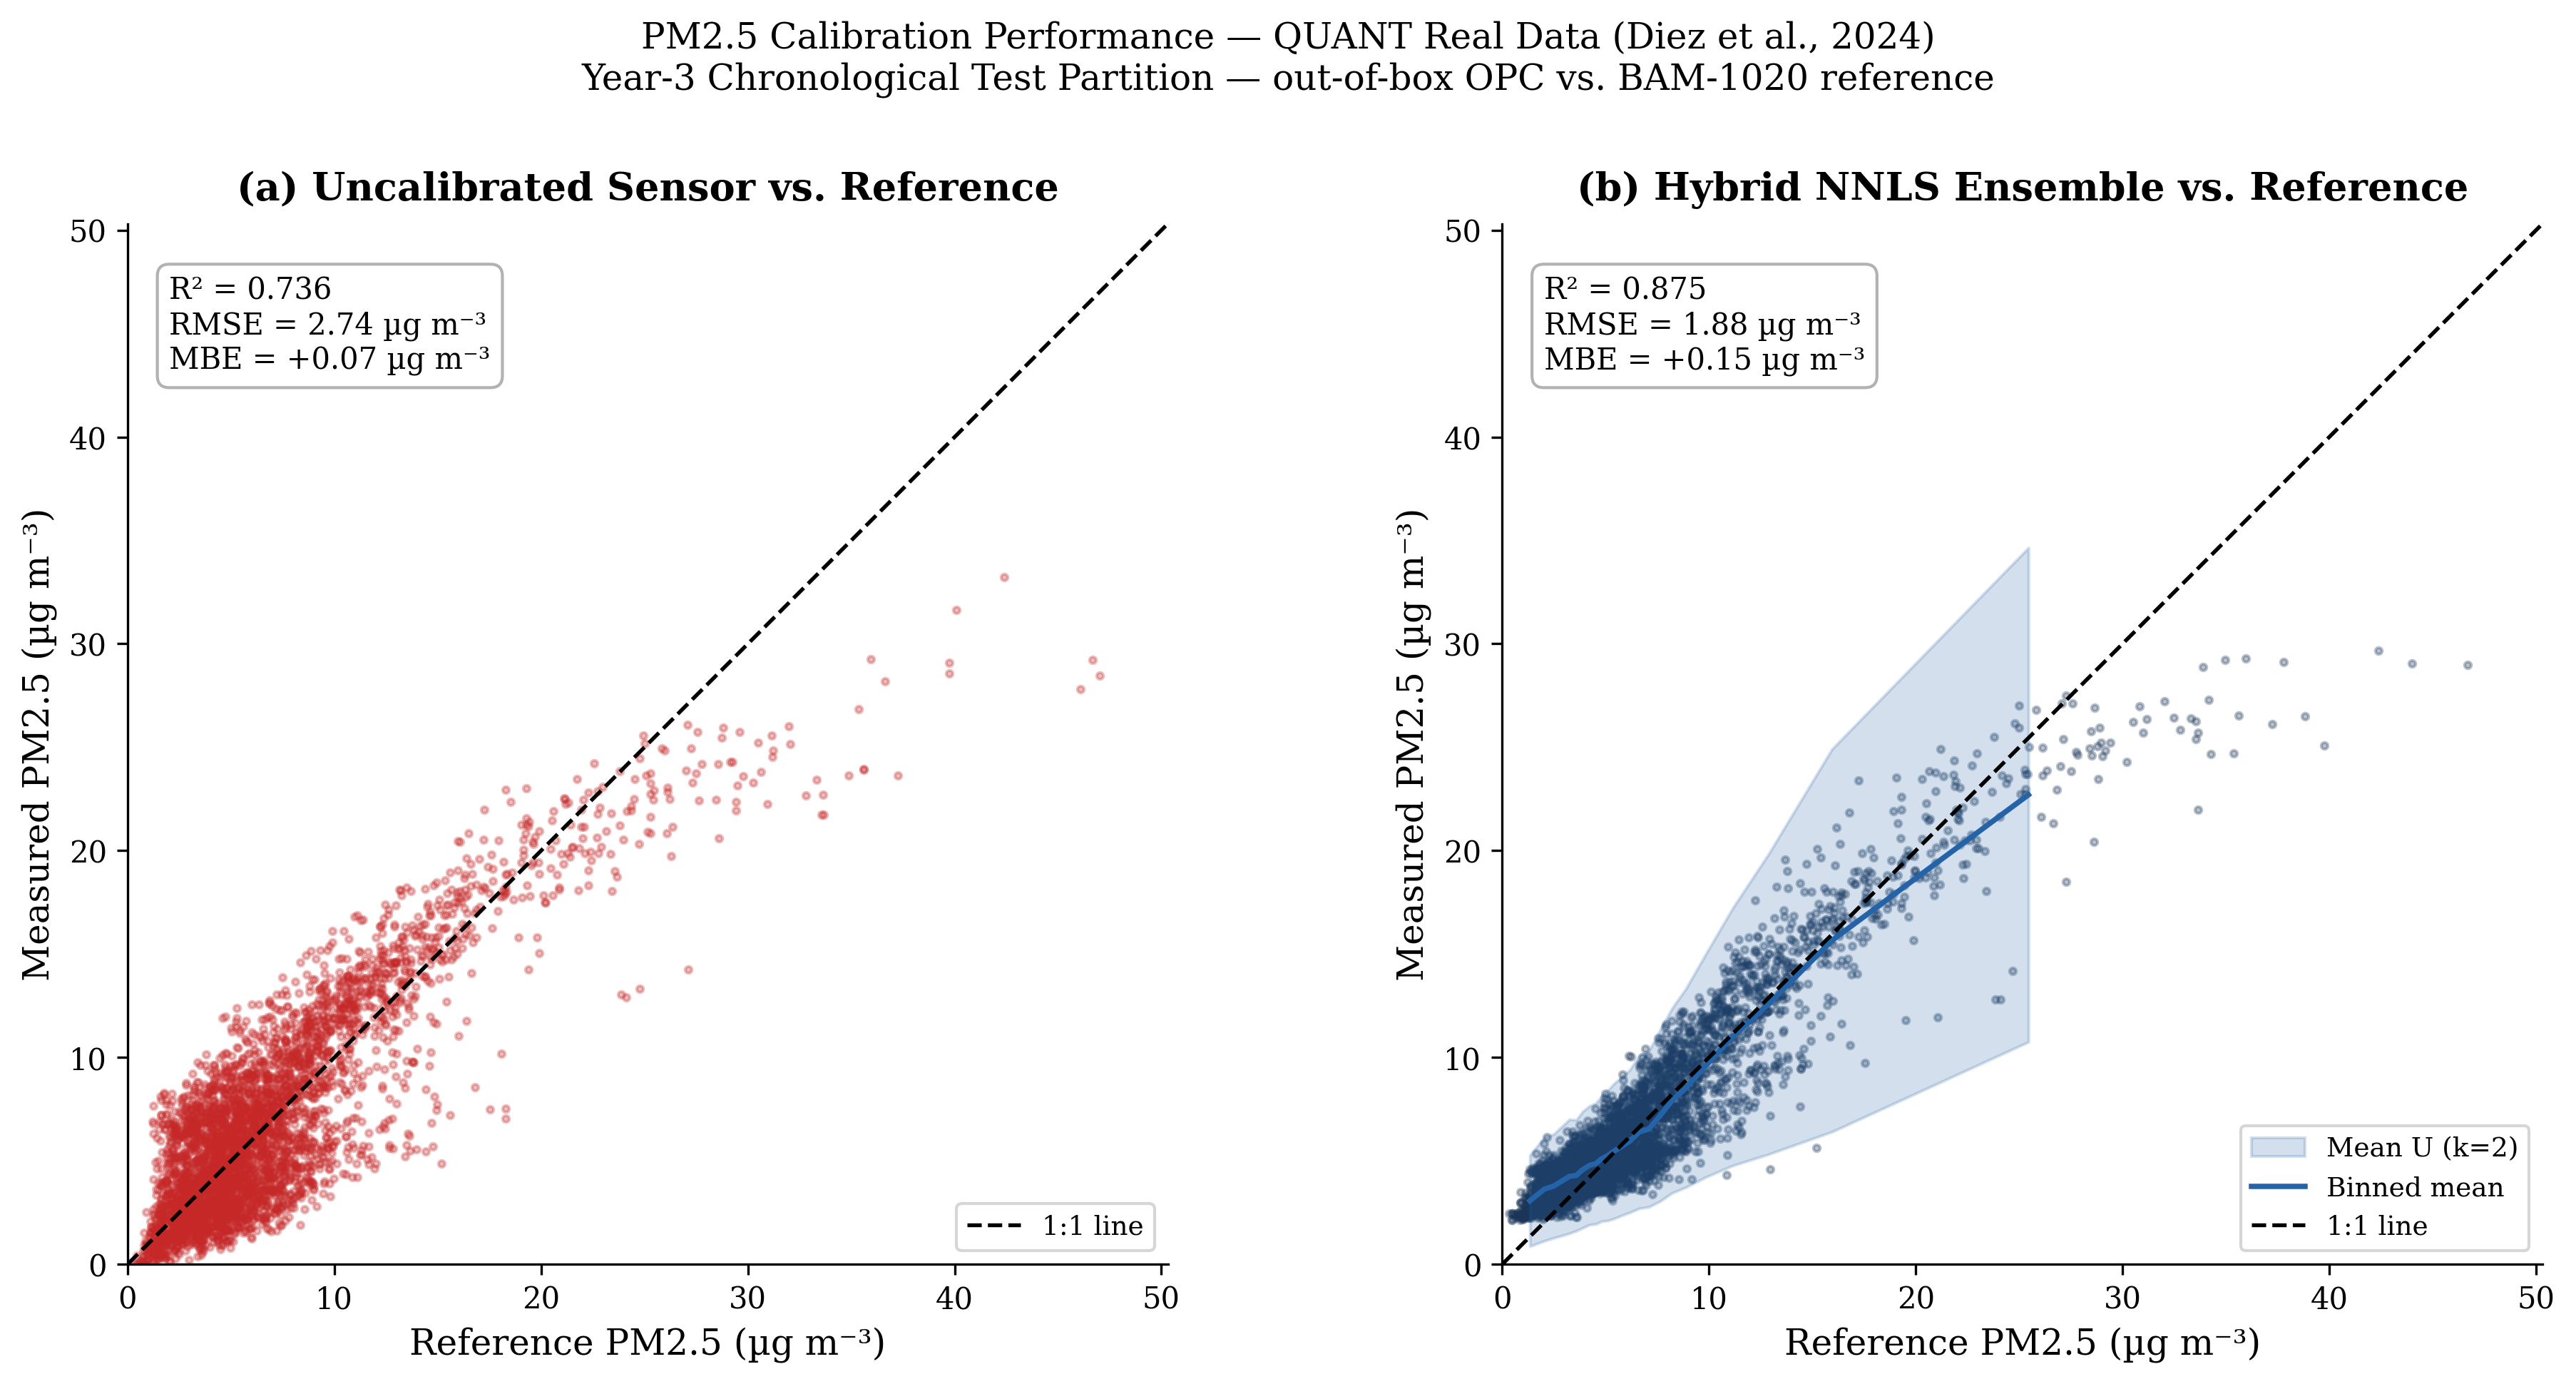

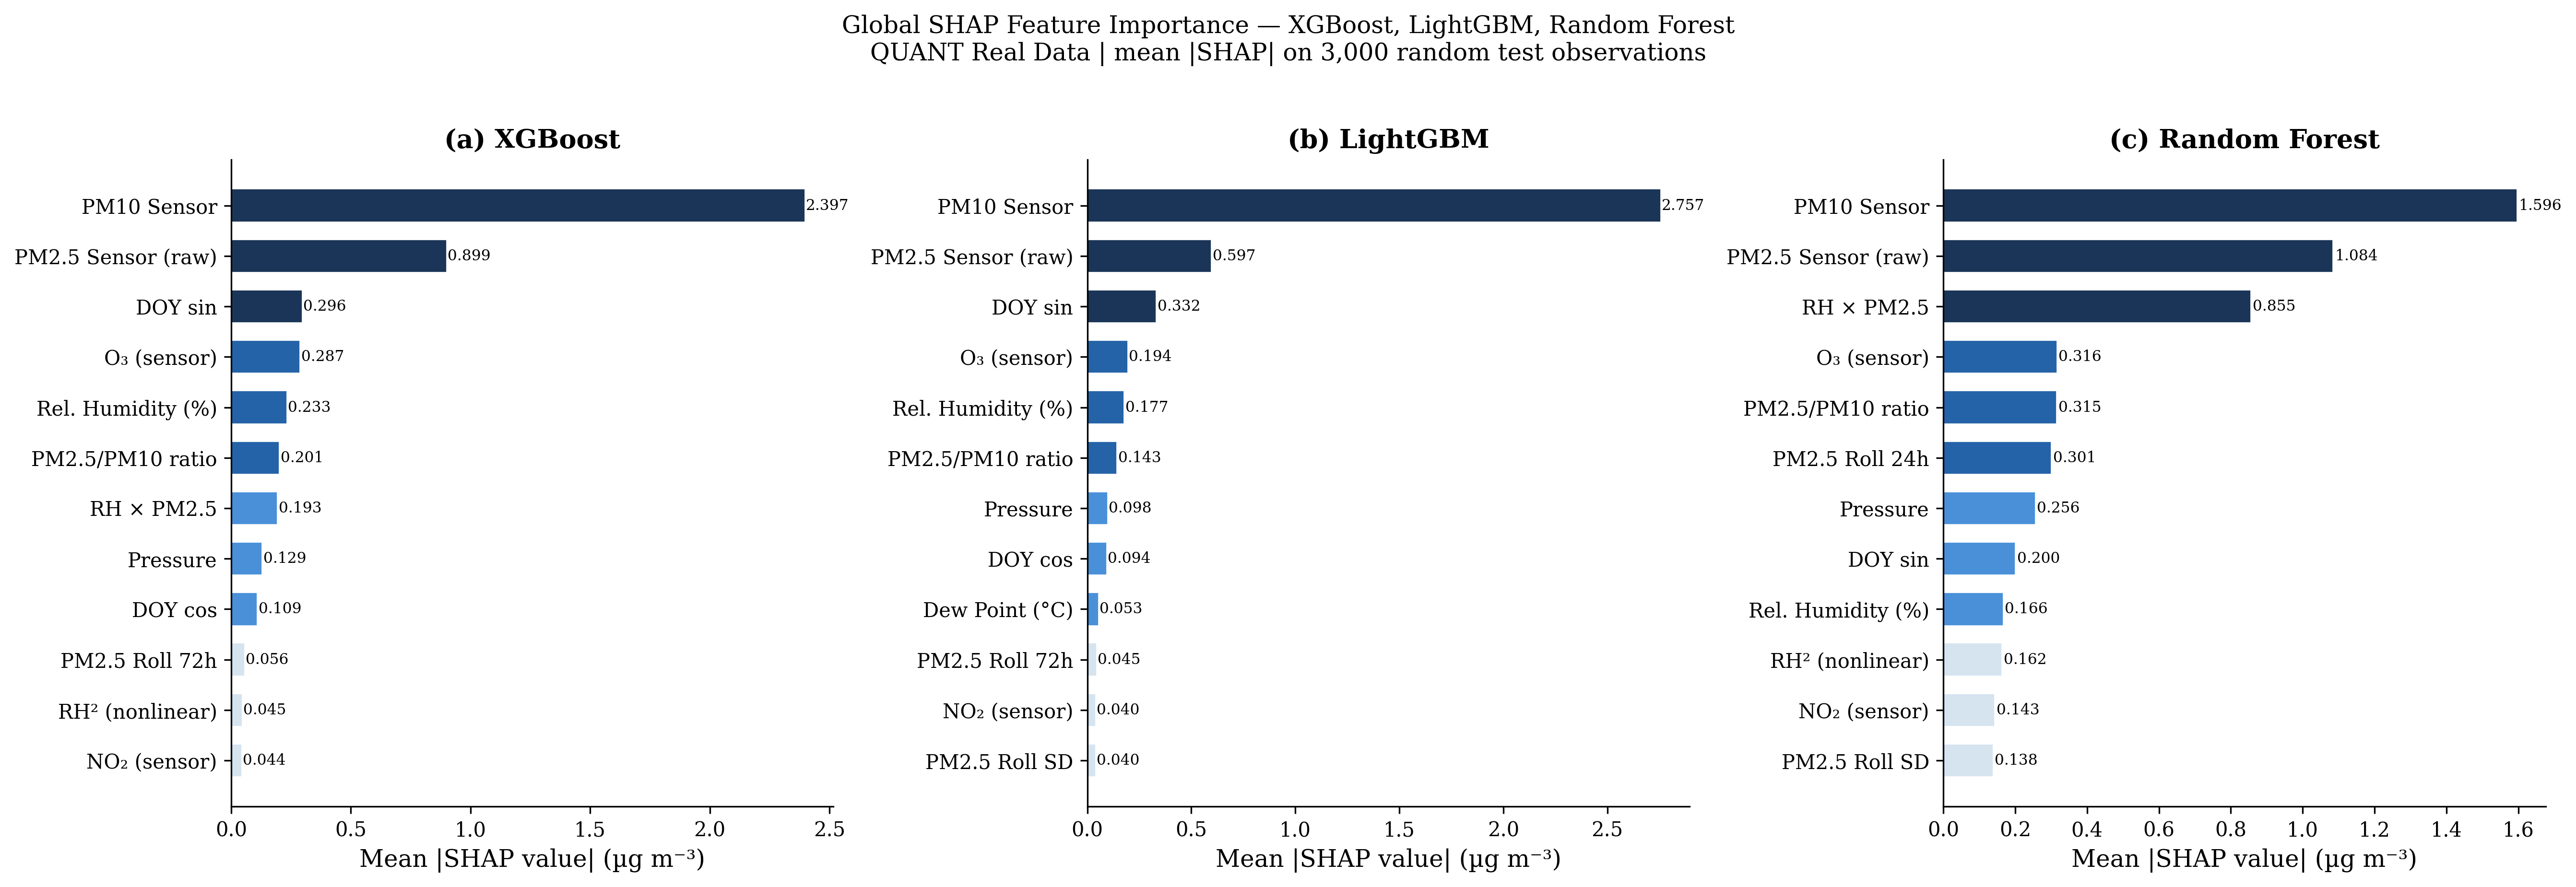

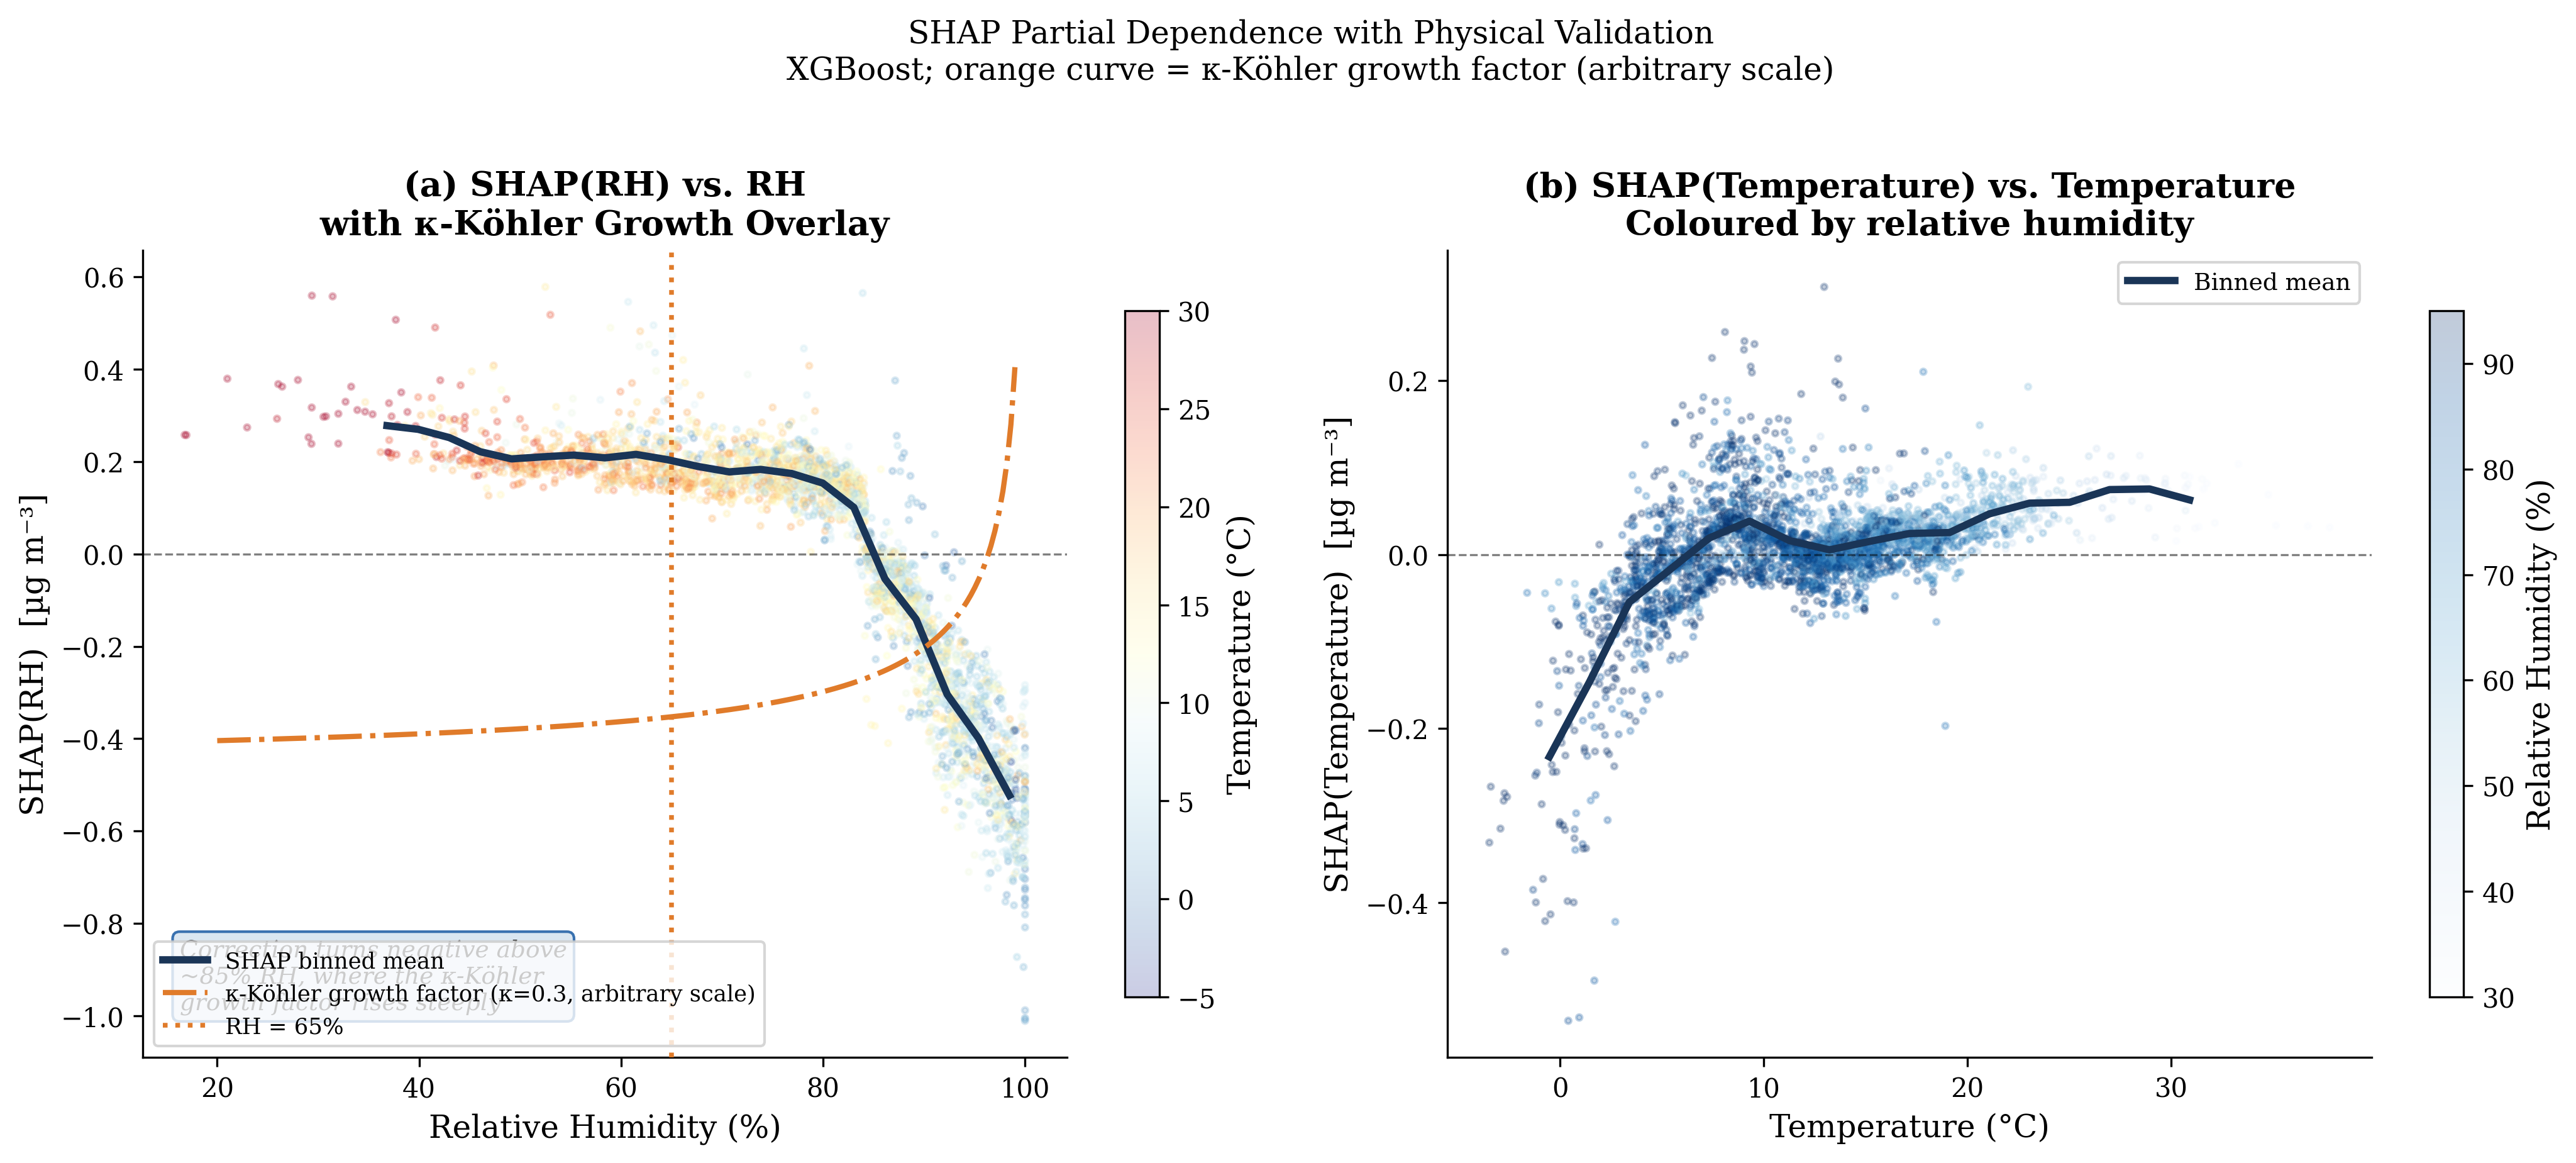

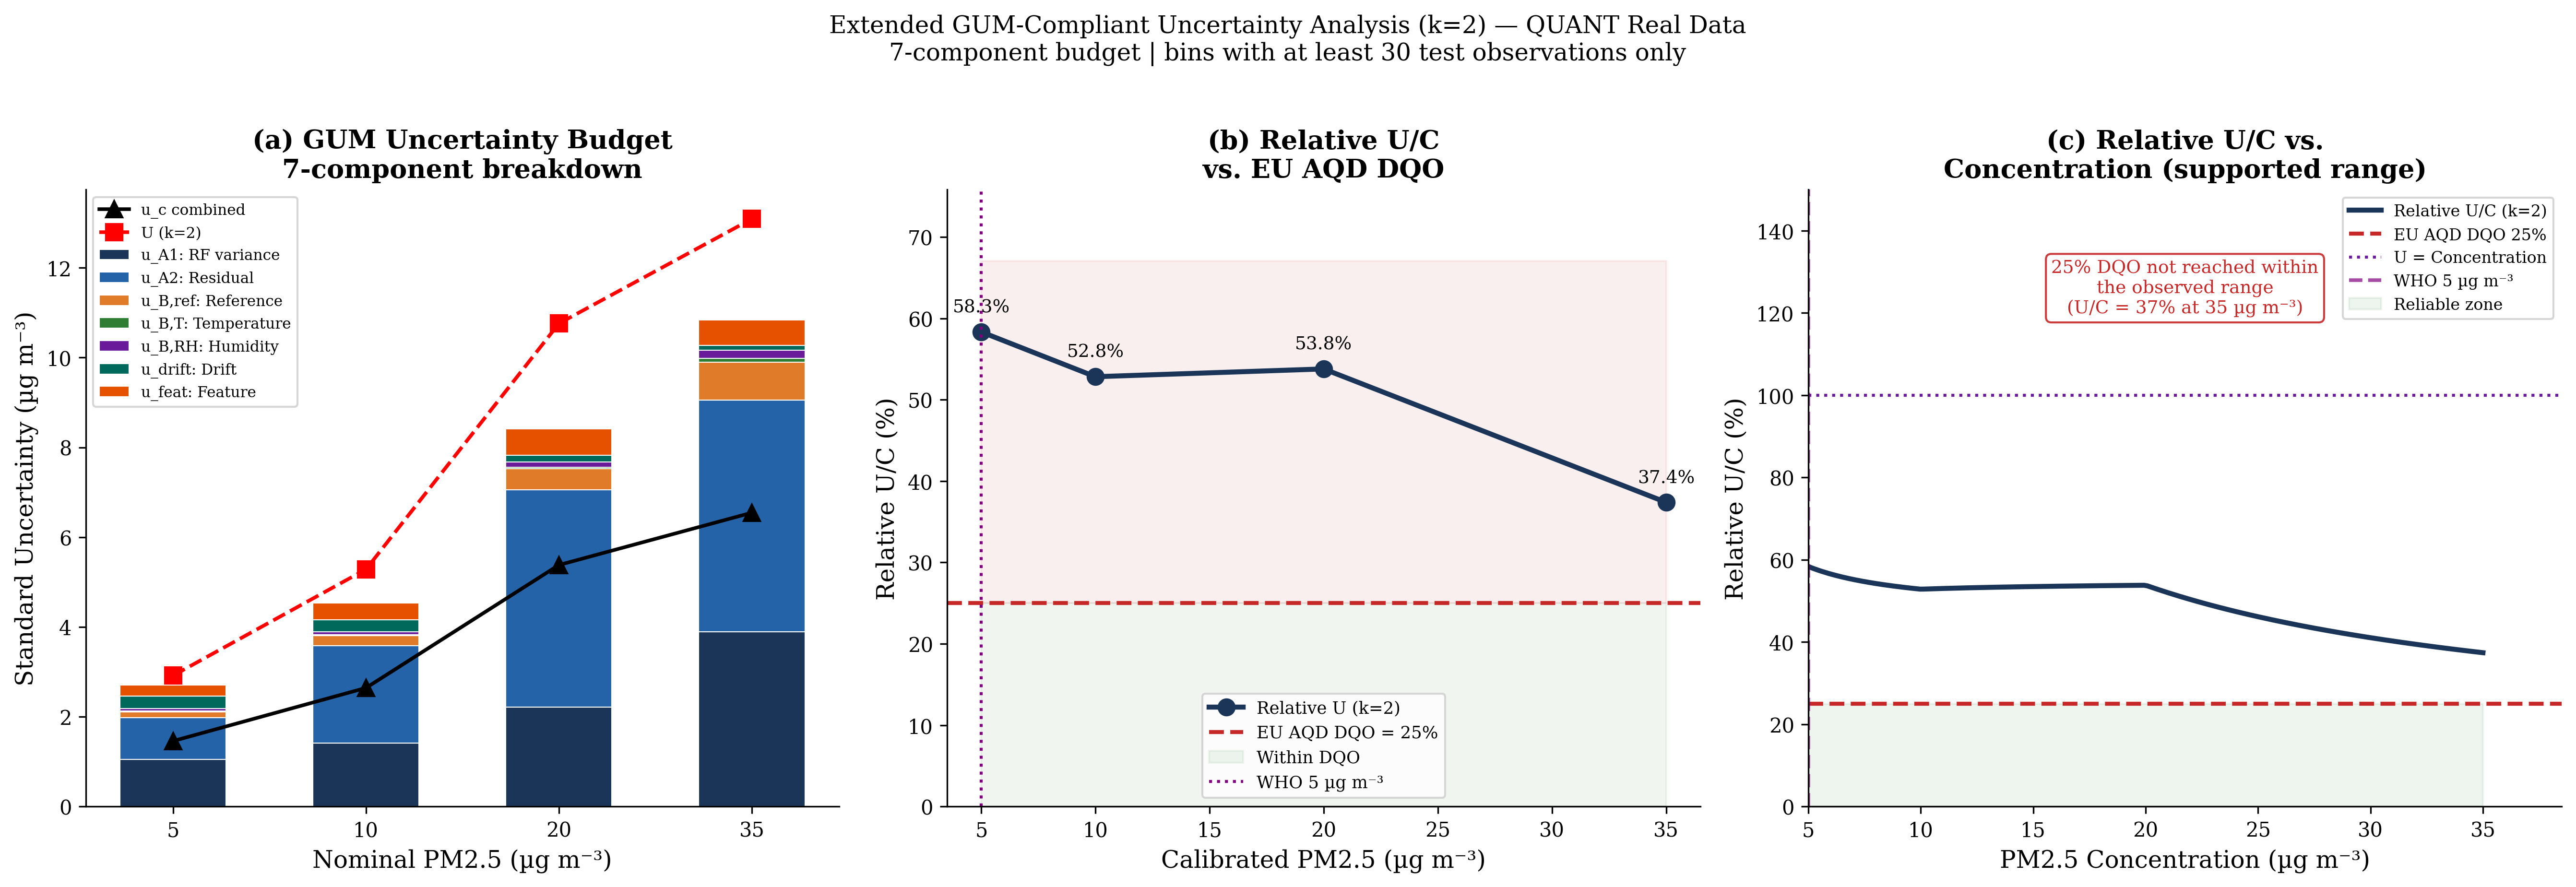

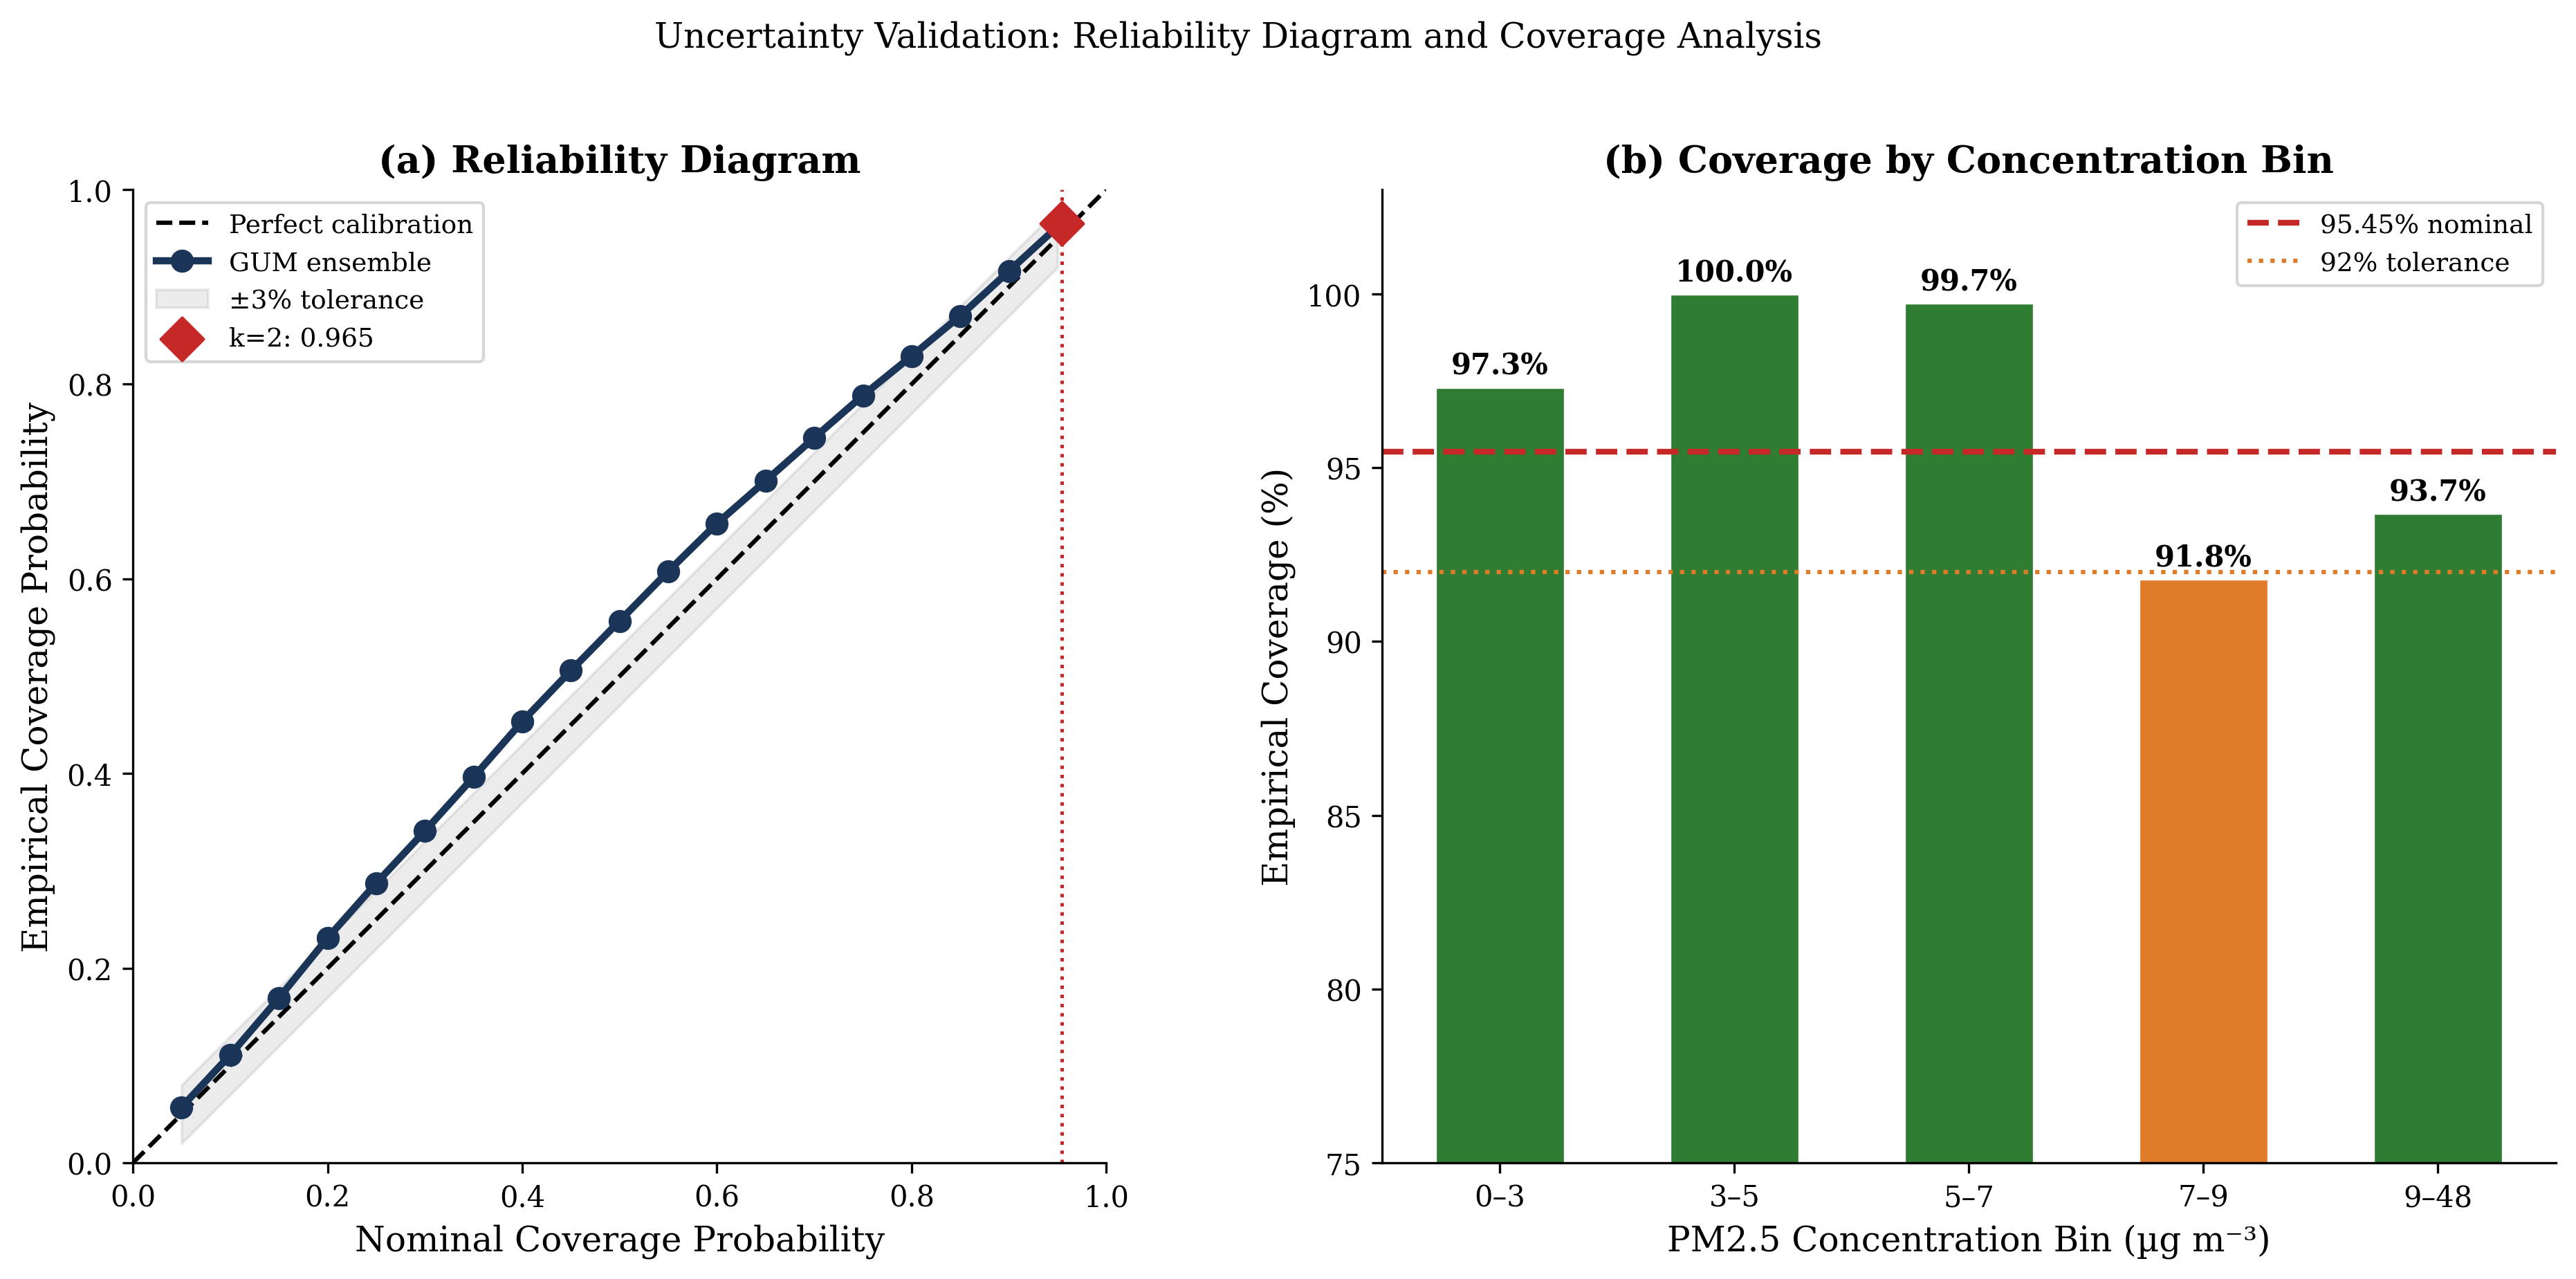

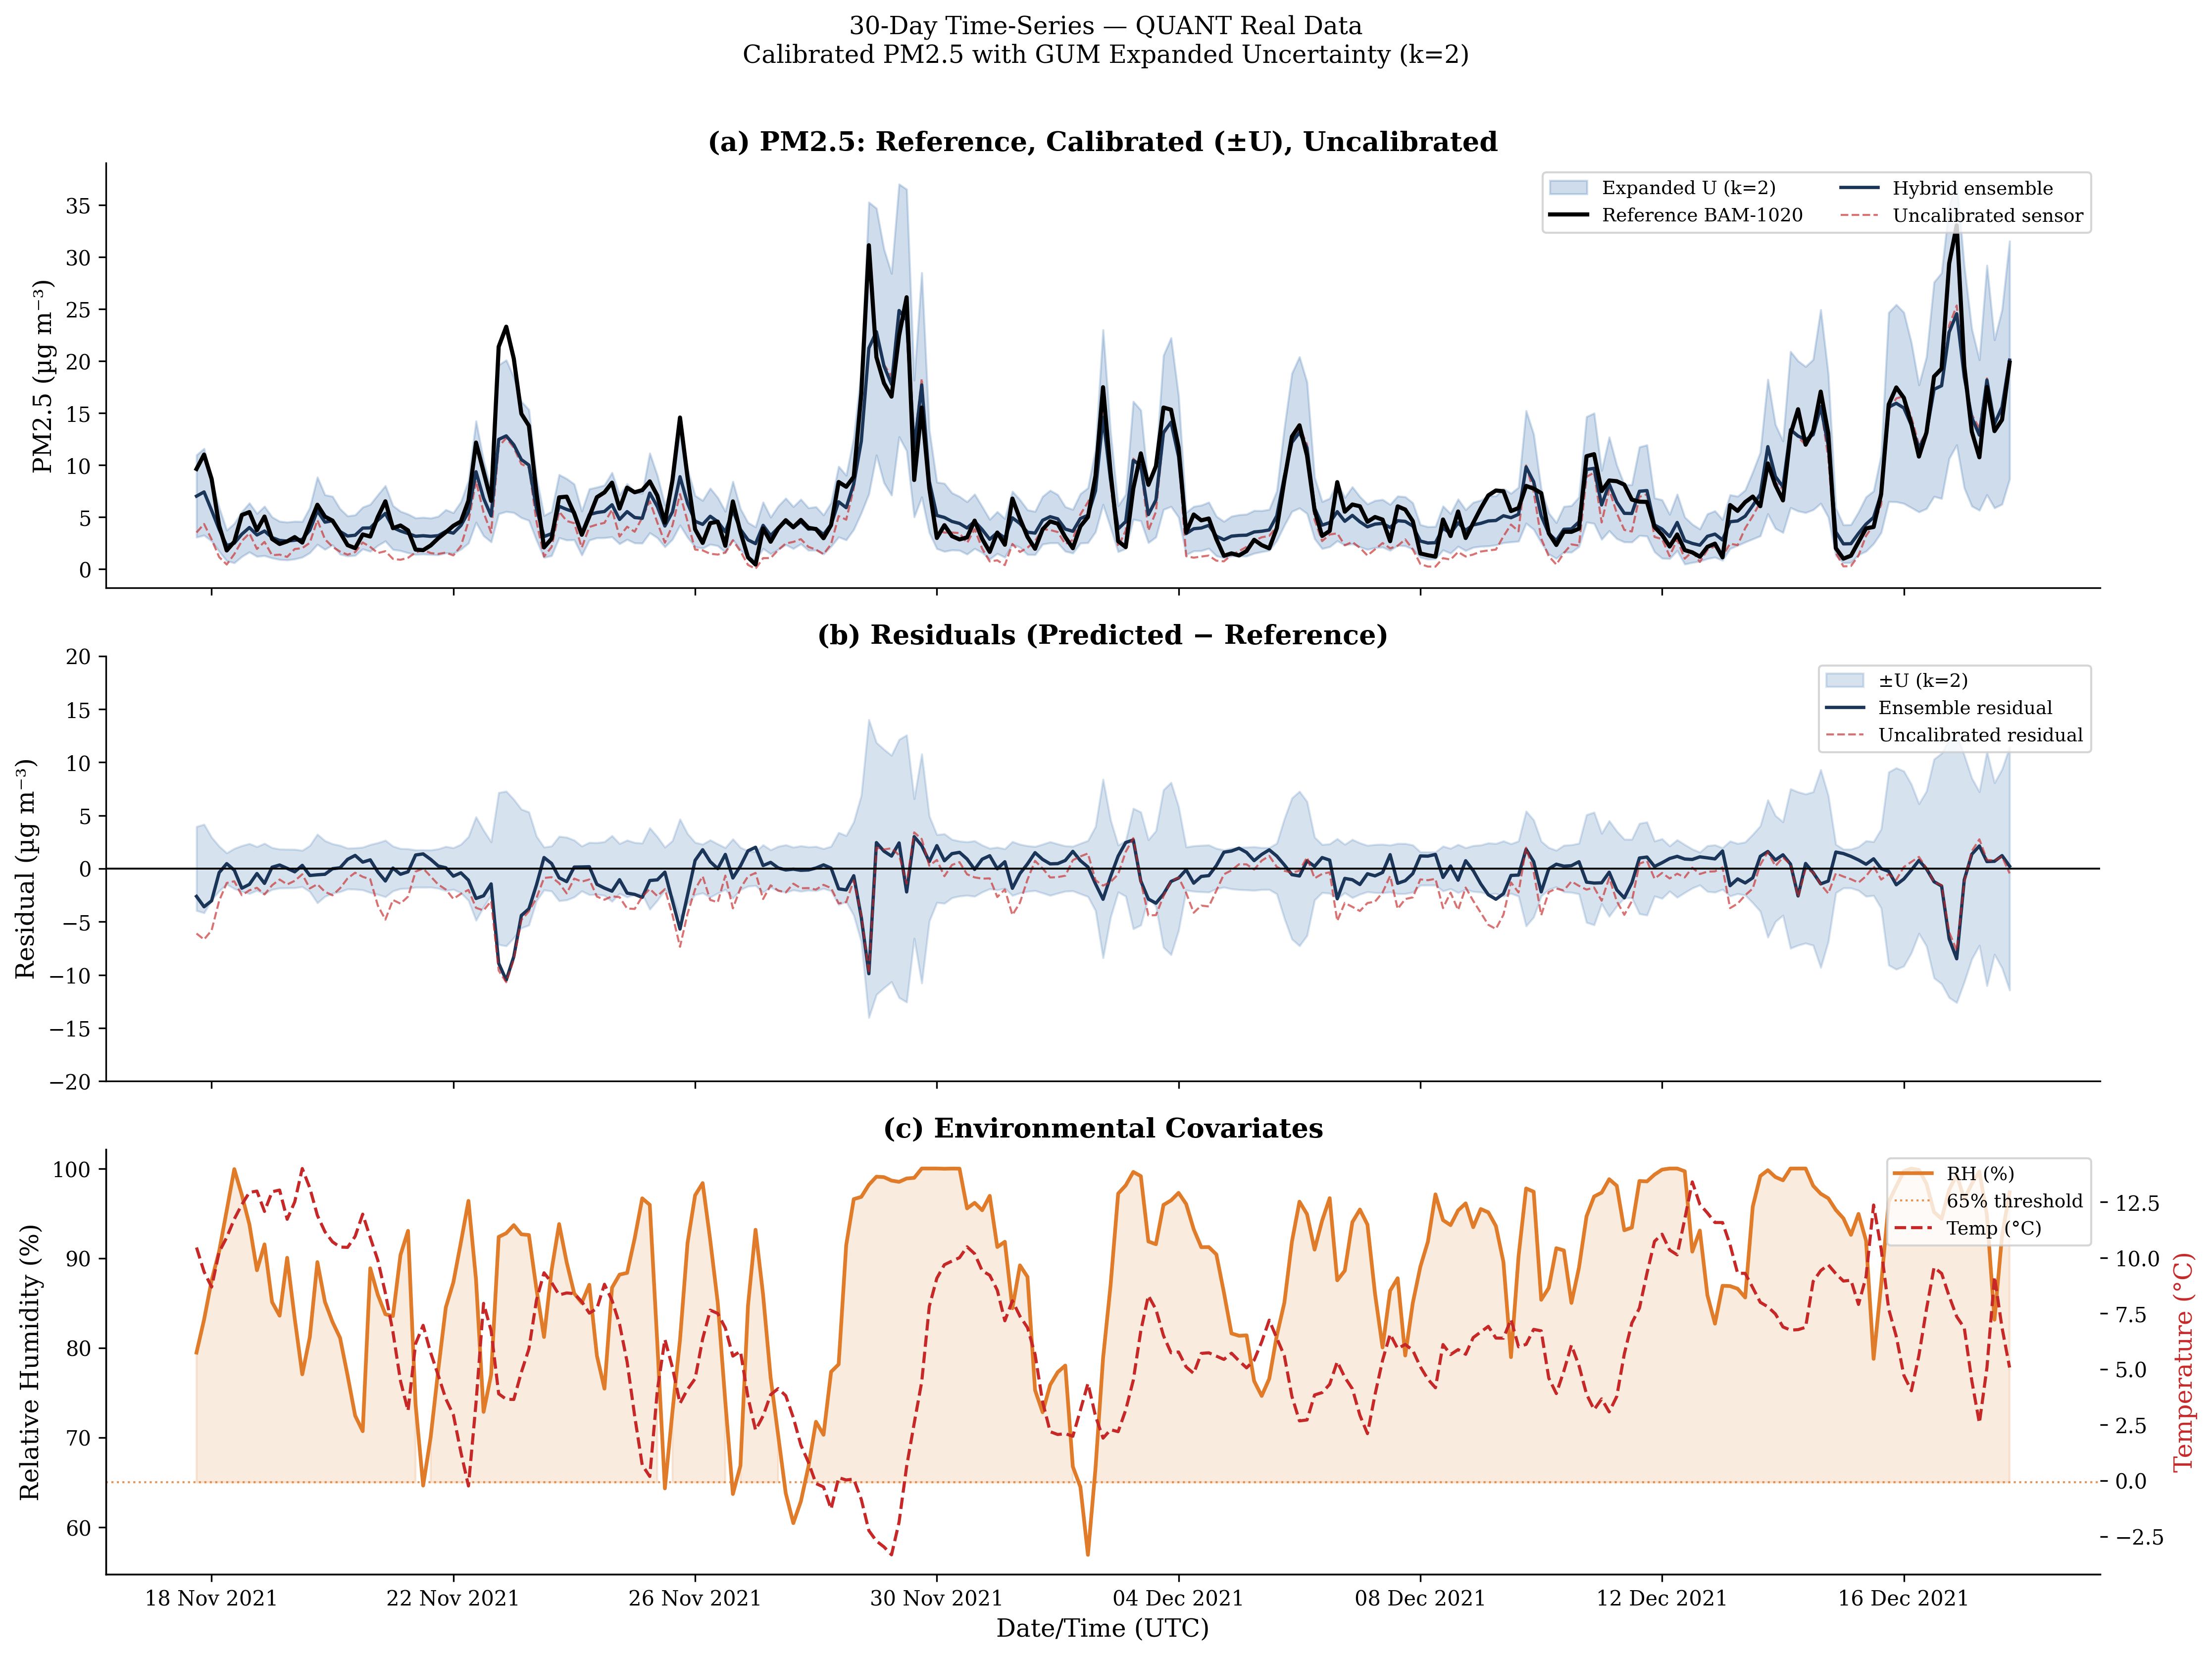

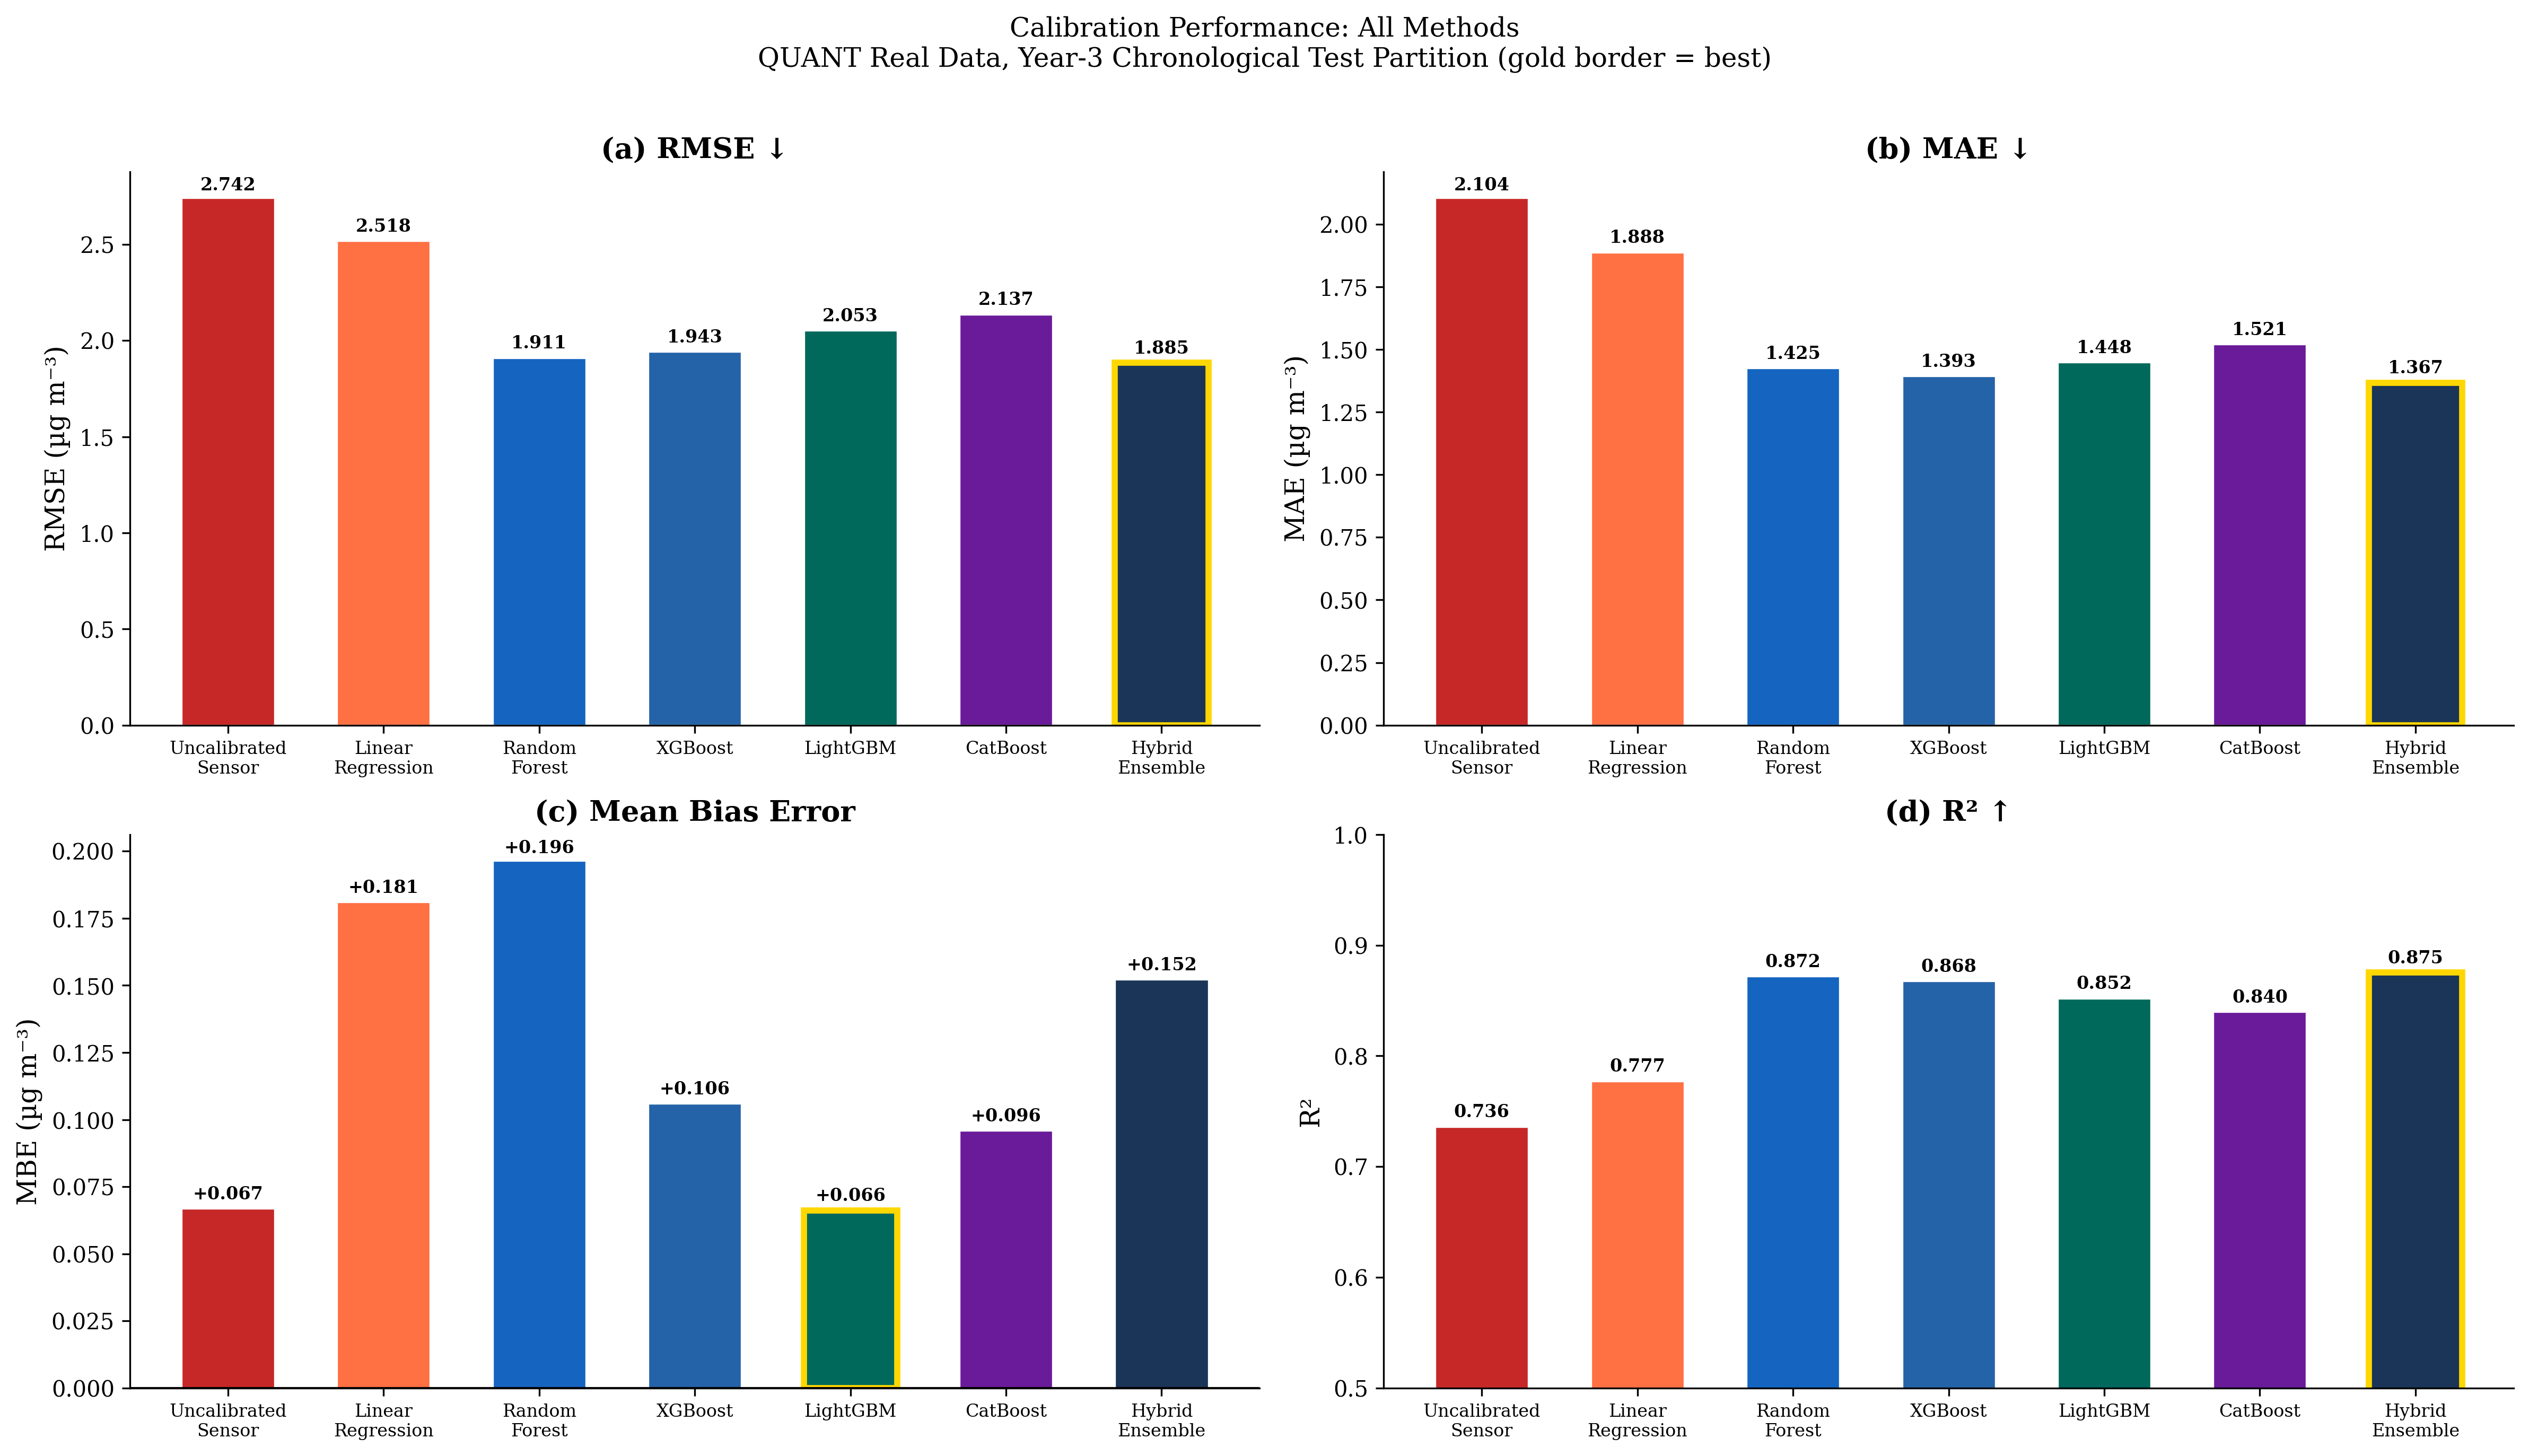

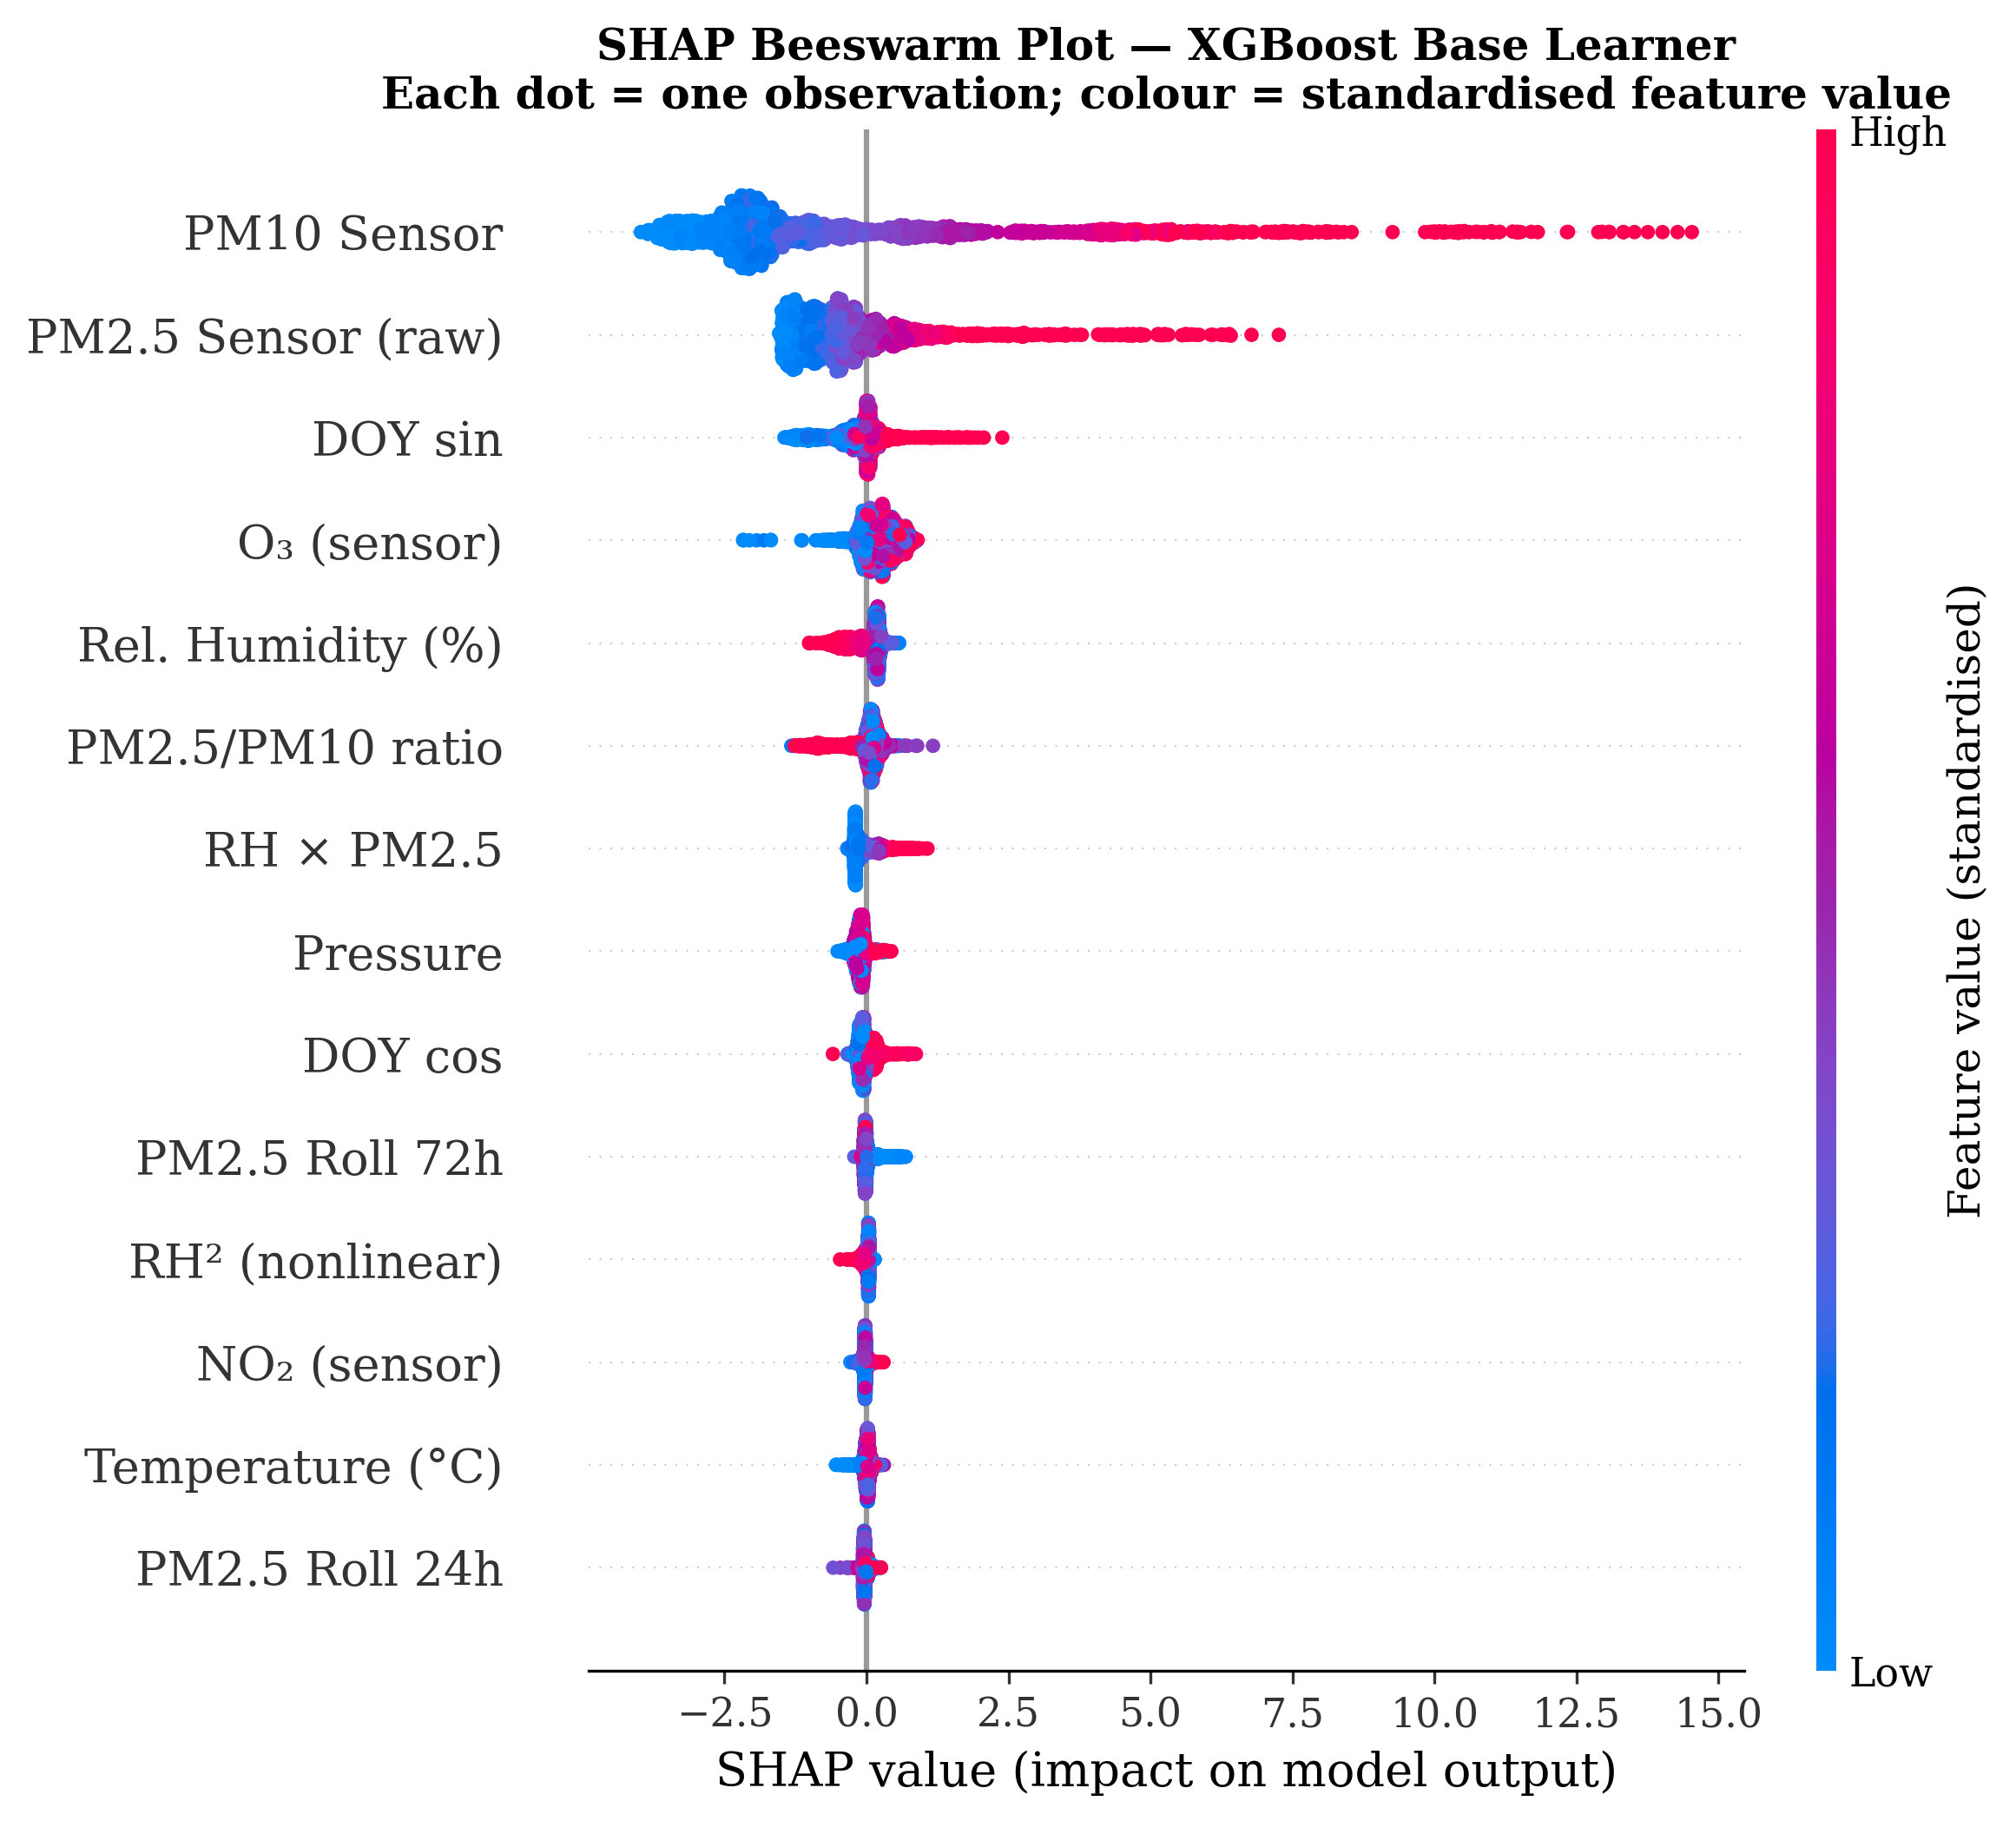

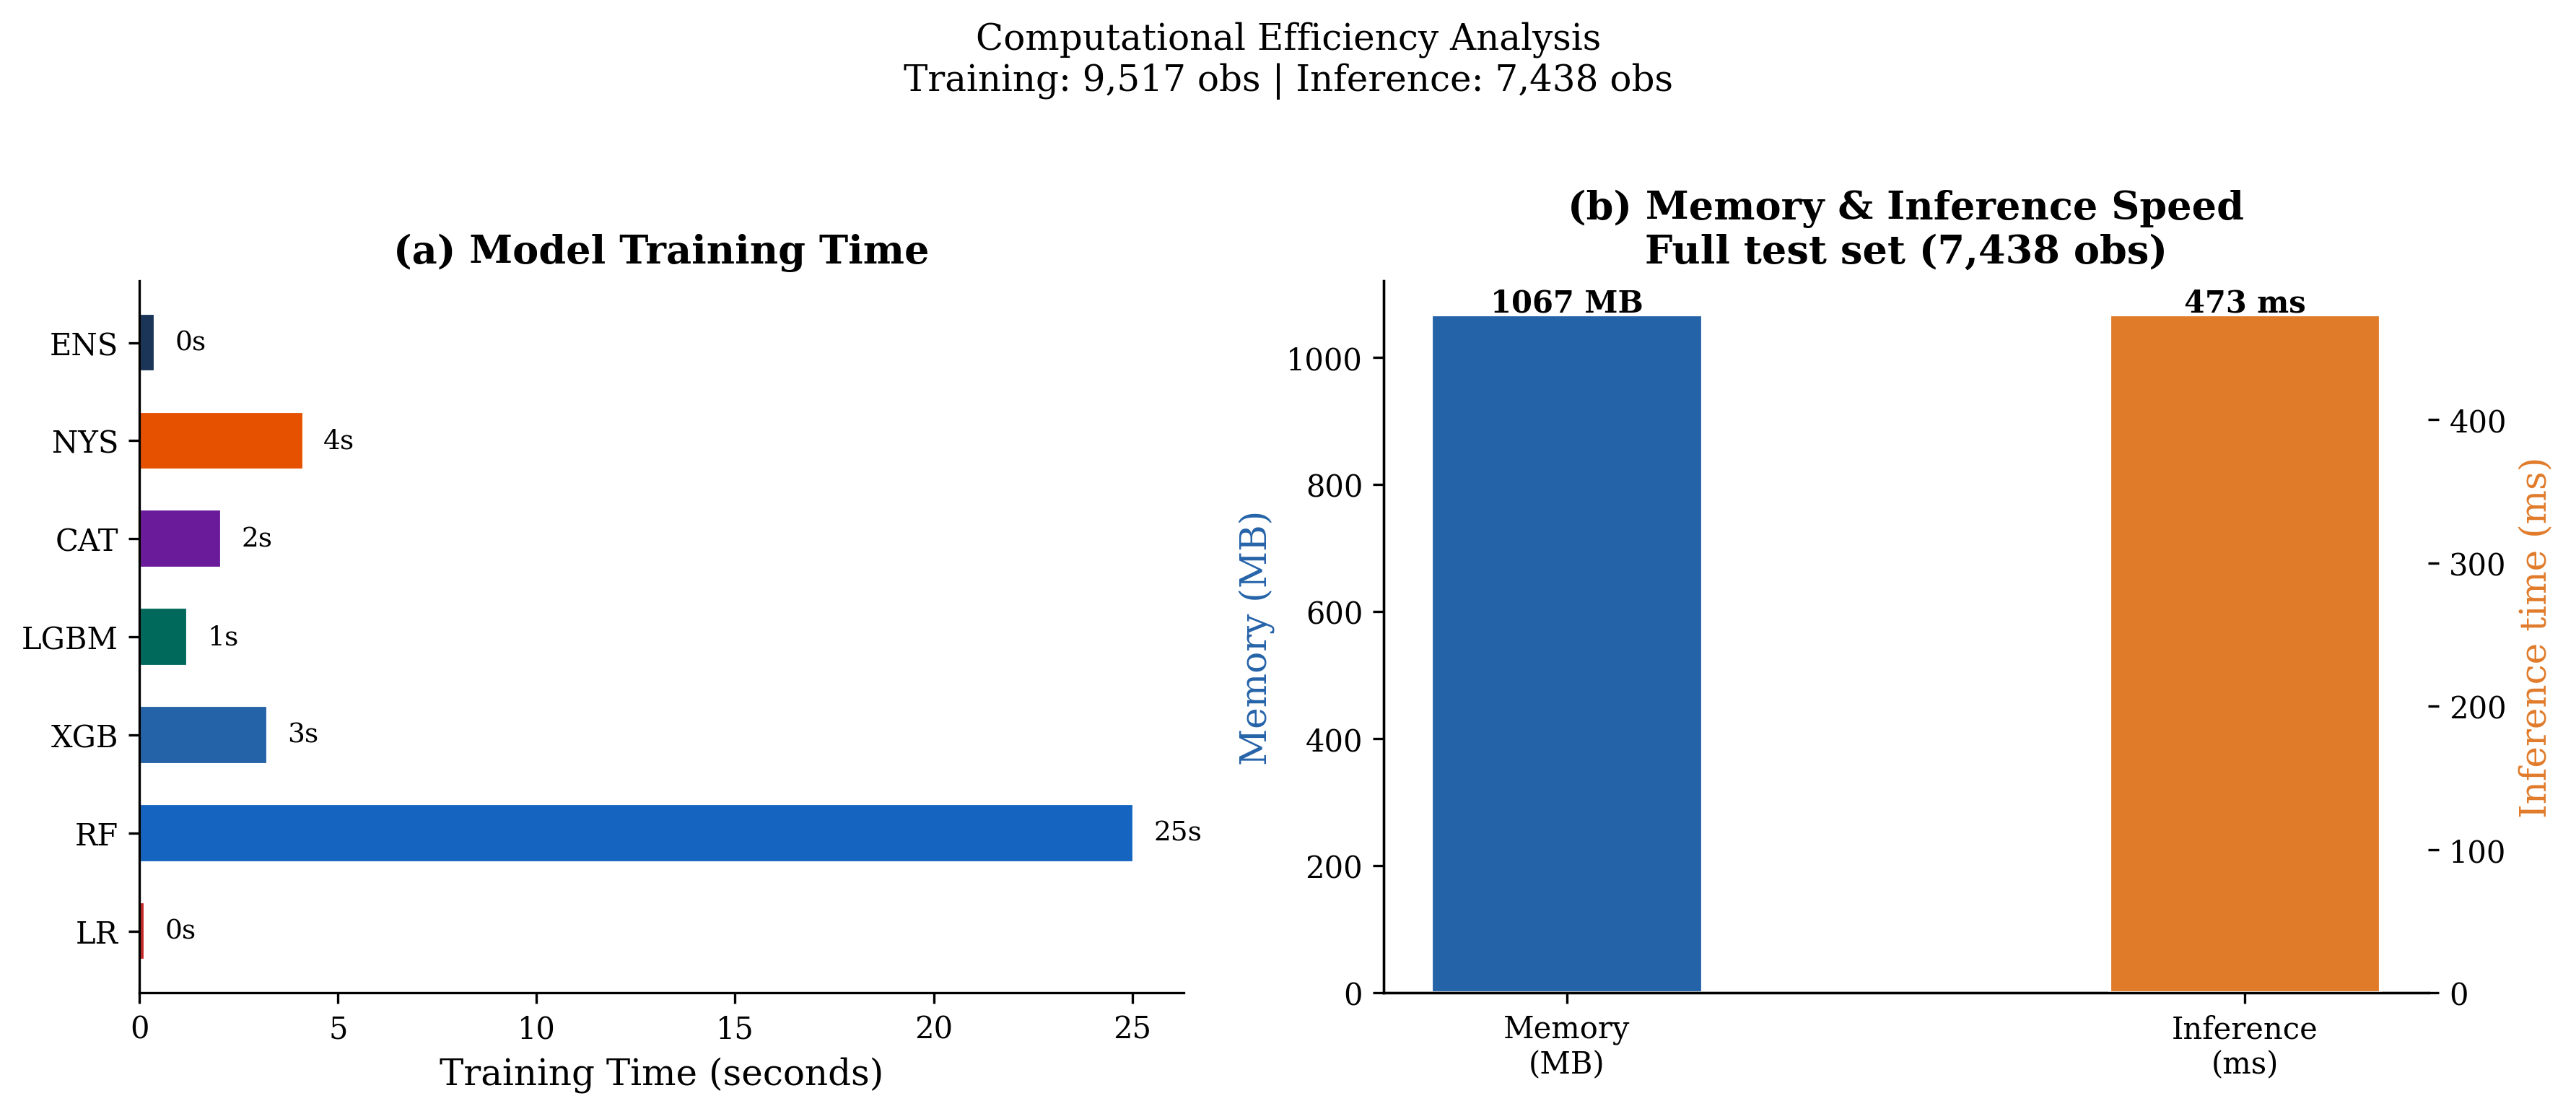

In [25]:
from IPython.display import Image, display

files = ["fig1_calibration_scatter.png","fig2_shap_importance.png","fig3_shap_dependence.png","fig4_uncertainty_budget.png","fig5_reliability_diagram.png","fig6_timeseries.png", "fig7_model_comparison.png", "fig8_shap_beeswarm.png","fig10_efficiency.png"]
for f in files:
    display(Image(f))